# The junction region, pixel by pixel

[junction_region.ipynb](junction_region.ipynb) shows *what* each step of the junction finder does. This notebook shows *how*, at the level of single pixels: which pixels a filter looks at, what number each pixel ends up with, and which pixels a step adds or removes.

It runs on **two real sections** from the same slide (assembloid pair 034-033), both with a junction drawn by hand:

- **The worked section**, `2025_09_26_Asssembloid_034-033_s13`. The finder's line lies a mean **15 µm** from the hand-drawn one. Every step is shown on it.
- **The failed section**, `2025_09_26_Asssembloid_034-033_s17`. The finder says *ok* and flags nothing, but its line lies about **340 µm** from the hand-drawn one. Where it matters, the same step is shown on it beside the worked one, and the last section, *Where the failed section goes wrong*, puts the evidence together.

In every figure the **hand-drawn line is cyan and dashed**; the finder's line is yellow.

The finder works on an **overview** of the scan: 4.9 µm per pixel, about 500 × 500 pixels for a whole section. Whole-section panels show it as a picture; zoomed panels show a few dozen pixels as squares, with the value printed inside each. Steps 0 and 8 go back to the scan itself and read a small window at full resolution (0.325 µm per pixel).

Every step calls the same function the viewer calls (`microscopy_viewer/junction.py`). Where a function does several things in a row, the cell does them one by one with the same lines of code, then checks that the result is **identical** to the function's (`assert`). So the numbers here are the numbers a batch run computes.

| Step | What, at the pixel level | Function |
|---|---|---|
| 0 | keep one pixel in every block of 15 × 15, or average the block | `build_overview`, `_block_mean` |
| 1 | per channel: Gaussian weights, a threshold; then all channels together, opening, closing, connected pieces | `tissue_mask` |
| 2 | each pixel minus the median of its neighbourhood; a normalised blur | `cell_density`, `has_cells` |
| 3 | half-range thresholds, the largest piece, distance through the tissue | `find_seeds` |
| 4 | a ratio of two blurs, raised to the 6th power | `line_cost` |
| 5 | pixels as a graph, the minimum cut | `_min_cut`, `split_tissue` |
| 5b | stations across the section, a curve that pays for turning | `straighten_cut` |
| 6 | touching pixels, a skeleton, a walk end to end, a running mean | `trace_interface` |
| 7 | pixels on the line, distance from them, the side of the line, a rim past the edge, rounding off | `_build_band` |
| 8 | the band's outline, filled on the full-resolution grid | `_outline`, `full_resolution_band` |
| 9 | the figures the status is read from, pixel by pixel | `tissue_metrics`, `quality_flags` |

**What it needs.** The two scans on `D:\Slidescanner extracted\` and the overviews cached by the evaluation (`junction_eval\overviews\`, made by `notebooks/validation/junction_tuning.py`). It only reads; nothing is written next to the data. No GPU. **Run All** from the top (a few minutes); each cell uses what the cells above it made.

In [1]:
from pathlib import Path
import ssl
import sys
from types import SimpleNamespace

# Some Python installations on Windows cannot read the Windows certificate store
# ("SSLError: [ASN1: NOT_ENOUGH_DATA]"). Nothing here uses the network, but reading
# a scan goes through dask, which imports a library that builds an SSL context on
# import and so fails for that reason. Where that is the case, skip the store.
try:
    ssl.create_default_context()
except ssl.SSLError:
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from scipy import ndimage

# The repository root, wherever the notebook is run from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "microscopy_viewer").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks" / "validation"))

from microscopy_viewer import fusion as fu
from microscopy_viewer import junction as jn
from microscopy_viewer import loaders
import junction_tuning as jt          # the cached overviews and hand-drawn lines of the evaluation

DATA = Path(r"D:\Slidescanner extracted")
WORKED = "2025_09_26_Asssembloid_034-033_s13"     # the finder's line is 15 µm from the hand-drawn one
FAILED = "2025_09_26_Asssembloid_034-033_s17"     # status ok, but its line is ~340 µm from the hand-drawn one

plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 10, "image.interpolation": "nearest"})

#: Colours for masks: 0 dark grey, then one colour per label.
MASK = ListedColormap(["#202020", "#e8e8e8"])
HALVES = ListedColormap(["#202020", "#3fa34d", "#d1495b"])
HAND = dict(color="cyan", ls="--", lw=1.6)          # the hand-drawn line, in every figure


def pixels(ax, values, title="", cmap="gray", fmt=None, origin=(0, 0), vmin=None, vmax=None,
           fontsize=6.5, every=None):
    """Draw *values* as a grid of square pixels, optionally with each value printed in its pixel.

    *origin* is the (row, col) of the top-left pixel, so a crop keeps the image's own
    coordinates on its axes. The grid lines are drawn only when the pixels are big enough to see.
    """
    values = np.asarray(values, dtype=float)
    h, w = values.shape
    r0, c0 = origin
    image = ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest",
                      extent=(c0 - 0.5, c0 + w - 0.5, r0 + h - 0.5, r0 - 0.5))
    if max(h, w) <= 60:
        ax.set_xticks(np.arange(c0 - 0.5, c0 + w, 1), minor=True)
        ax.set_yticks(np.arange(r0 - 0.5, r0 + h, 1), minor=True)
        ax.grid(which="minor", color="0.55", lw=0.25 if max(h, w) > 30 else 0.5)
    step = every or max(1, int(np.ceil(max(h, w) / 8)))
    ax.set_xticks(np.arange(c0, c0 + w, step))
    ax.set_yticks(np.arange(r0, r0 + h, step))
    ax.tick_params(which="both", length=0, labelsize=7)
    ax.set_title(title)
    if fmt:
        for (i, j), v in np.ndenumerate(values):
            if np.isfinite(v):
                r, g, b, _ = image.cmap(image.norm(v))
                dark = 0.299 * r + 0.587 * g + 0.114 * b < 0.5
                ax.text(c0 + j, r0 + i, format(v, fmt), ha="center", va="center",
                        fontsize=fontsize, color="white" if dark else "black")
    return image


def edges(ax, mask, color="yellow", lw=1.5, origin=(0, 0), against=None):
    """Outline *mask* along the pixel edges themselves (not a smoothed contour).

    With *against*, only the edges where a pixel of *mask* meets a pixel of *against*.
    """
    m = np.pad(np.asarray(mask, dtype=bool), 1)
    o = ~m if against is None else np.pad(np.asarray(against, dtype=bool), 1)
    r0, c0 = origin
    segments = []
    between_cols = (m[:, 1:] & o[:, :-1]) | (o[:, 1:] & m[:, :-1])
    for i, j in zip(*np.nonzero(between_cols)):                # an edge between two columns
        x, y = c0 + j - 0.5, r0 + i - 1
        segments.append([(x, y - 0.5), (x, y + 0.5)])
    between_rows = (m[1:, :] & o[:-1, :]) | (o[1:, :] & m[:-1, :])
    for i, j in zip(*np.nonzero(between_rows)):                # an edge between two rows
        x, y = c0 + j - 1, r0 + i - 0.5
        segments.append([(x - 0.5, y), (x + 0.5, y)])
    ax.add_collection(LineCollection(segments, colors=color, linewidths=lw))


def window(ax, r0, c0, h, w, color="cyan"):
    """Mark the crop that a zoomed panel shows."""
    ax.add_patch(Rectangle((c0 - 0.5, r0 - 0.5), w, h, fill=False, ec=color, lw=1.5))


def limits(ax, z):
    """Hold a panel to the crop (r0, c0, h, w), whatever is drawn over it."""
    r0, c0, h, w = z
    ax.set_xlim(c0 - 0.5, c0 + w - 0.5)
    ax.set_ylim(r0 + h - 0.5, r0 - 0.5)


def crop(array, r0, c0, h, w):
    return np.asarray(array)[r0:r0 + h, c0:c0 + w]


def tint(ax, mask, color, alpha=0.55, origin=(0, 0)):
    """Paint the pixels of *mask* in *color*, leaving the rest as they are."""
    mask = np.asarray(mask, dtype=bool)
    h, w = mask.shape
    r0, c0 = origin
    rgba = np.zeros((h, w, 4))
    rgba[mask] = (*plt.matplotlib.colors.to_rgb(color), alpha)
    ax.imshow(rgba, interpolation="nearest", extent=(c0 - 0.5, c0 + w - 0.5, r0 + h - 0.5, r0 - 0.5))


def bbox(mask, pad=6):
    """The crop (r0, c0, h, w) holding *mask*, with *pad* pixels round it."""
    rows, cols = np.nonzero(mask)
    r0, c0 = max(int(rows.min()) - pad, 0), max(int(cols.min()) - pad, 0)
    return r0, c0, int(rows.max()) + pad - r0, int(cols.max()) + pad - c0


def stretch(plane, low=1.0, high=99.8):
    """A plane scaled to 0-1 between two percentiles of its non-zero pixels, for display only."""
    a, b = np.percentile(plane[plane > 0], (low, high))
    return np.clip((plane - a) / max(b - a, 1e-6), 0, 1)


def hand(ax, case, **style):
    """The hand-drawn line of *case*, on overview pixels."""
    line = case.manual_line / case.um
    ax.plot(line[:, 1], line[:, 0], **{**HAND, **style})


def auto(ax, line_um, um, **style):
    """A line in µm (the finder's, by default in yellow), on overview pixels."""
    if line_um is not None:
        ax.plot(line_um[:, 1] / um, line_um[:, 0] / um, **{"color": "yellow", "lw": 1.8, **style})


def boundary(sides):
    """Pixels of side 1 touching side 2: where a cut runs."""
    return (sides == 1) & ndimage.binary_dilation(sides == 2)


def line_of(sides, um):
    """The junction line (µm) traced along the boundary of two halves."""
    line = jn.trace_interface(sides, um)
    return None if line is None else line * um


def off_by(case, line_um):
    """How far a line is from the hand-drawn one: mean (µm), 95th percentile (µm), share within 100 µm."""
    if line_um is None:
        return float("nan"), float("nan"), 0.0
    return jt.line_distance(case.manual_line, line_um, case.region, case.um)


def run_steps(name):
    """Every intermediate the finder makes on one section, each from the engine's own function.

    The step cells below redo these one operation at a time on the worked section; this is
    what the failed section is drawn from beside it.
    """
    overview, manual_band, manual_line, base = jt.load_case(name)
    options = jn.JunctionOptions(save=False, width_um=base["width_um"], gap_um=base["gap_um"])
    um, channels = overview.um, overview.channels
    valid = (channels > 0).all(axis=0)
    tissue = jn.tissue_mask(channels[overview.nuclear], valid, um,
                            jn._others(channels, overview.nuclear, options.tissue_all_channels))
    filled = ndimage.binary_fill_holes(tissue)
    density = jn.cell_density(channels[overview.label], tissue, filled, um,
                              median=options.use_median, median_um=options.median_um)
    other_density = None
    if overview.other is not None and jn.has_cells(channels[overview.other], tissue, um):
        other_density = jn.cell_density(channels[overview.other], tissue, filled, um,
                                        median=options.use_median, median_um=options.median_um)
    hot, cold, rule = jn.find_seeds(filled, density, other_density)
    cost = jn.line_cost(overview.nuclear_mean, filled, um)
    halves_free = jn.split_tissue(filled, density, um, cost, seeds=(hot, cold))
    halves = jn.split_tissue(filled, density, um, cost, seeds=(hot, cold), bend_um=options.bend_um)
    result = jn.find_junction(overview, options)
    assert np.array_equal(result.tissue, tissue) and np.array_equal(result.halves, halves)
    region = ndimage.binary_dilation(filled, iterations=max(1, int(np.ceil(base["margin_um"] / um))))
    return SimpleNamespace(name=name, overview=overview, options=options, base=base, um=um,
                           manual_band=manual_band, manual_line=manual_line, valid=valid, tissue=tissue,
                           filled=filled, density=density, other_density=other_density, hot=hot, cold=cold,
                           rule=rule, cost=cost, halves_free=halves_free, halves=halves, result=result,
                           region=region, view=bbox(filled))


W, F = run_steps(WORKED), run_steps(FAILED)
for case, tag in ((W, "worked"), (F, "failed")):
    mean, hd95, within = off_by(case, case.result.line_um)
    print(f"{tag}: {case.name}  status {case.result.status}  flags: {'; '.join(case.result.flags) or 'none'}\n"
          f"        line vs hand-drawn: mean {mean:.0f} µm, 95th percentile {hd95:.0f} µm, {100 * within:.0f} % within 100 µm")

worked: 2025_09_26_Asssembloid_034-033_s13  status ok  flags: none
        line vs hand-drawn: mean 15 µm, 95th percentile 43 µm, 100 % within 100 µm
failed: 2025_09_26_Asssembloid_034-033_s17  status ok  flags: none
        line vs hand-drawn: mean 341 µm, 95th percentile 881 µm, 36 % within 100 µm


## The two sections

Both are from the same slide, cut a few sections apart from the same assembloid. Each panel is the overview the finder works on, coloured as the scan's three channels: **red** AF555 (the label of the other organoid), **green** AF488 (GFP, the labelled cells), **blue** AF405 (DAPI, all nuclei).

In both, the labelled organoid is the lower one and the other organoid the upper one; the hand-drawn junction runs roughly left to right between them. In both, the DAPI shows **dark vertical cracks** across the upper organoid. In the failed section they are wider, and some are open **tears**: slits with no tissue in them.

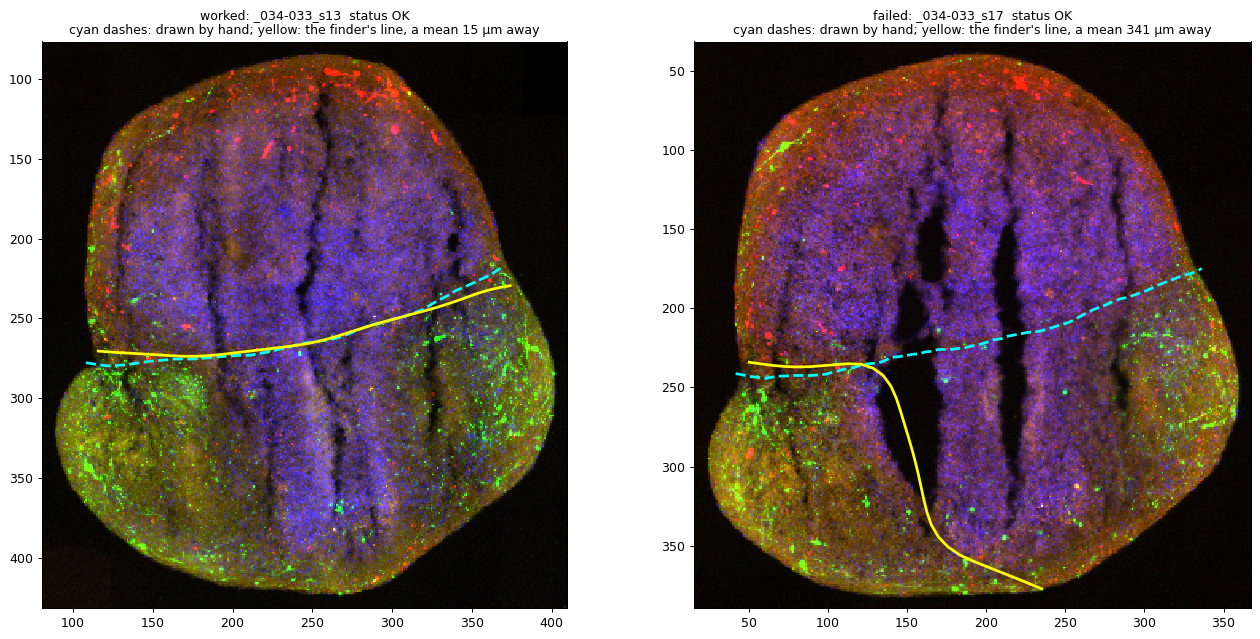

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.2))
for ax, case, tag in zip(axes, (W, F), ("worked", "failed")):
    ov = case.overview
    rgb = np.dstack([stretch(ov.channels[ov.other]), stretch(ov.channels[ov.label]), stretch(ov.channels[ov.nuclear])])
    ax.imshow(rgb)
    hand(ax, case, lw=2.2)
    auto(ax, case.result.line_um, case.um, lw=2.2)
    limits(ax, case.view)
    mean = off_by(case, case.result.line_um)[0]
    ax.set_title(f"{tag}: {case.name[-12:]}  status {case.result.status.upper()}\n"
                 f"cyan dashes: drawn by hand; yellow: the finder's line, a mean {mean:.0f} µm away")
plt.tight_layout()

## Step 0 — the overview: keep one pixel per block, or average the block

The scan is 0.325 µm per pixel, about 7 600 × 7 600 pixels per plane. The overview is made at about **5 µm per pixel**: `step = round(5 / 0.325) = 15`, so each overview pixel stands for a block of **15 × 15** full-resolution pixels, and the overview pixel is 15 × 0.325 = **4.875 µm**.

Each channel is first flattened over Z by taking the **maximum** of every pixel over the planes (this scan has three). Then:

- **every channel**: overview pixel *(r, c)* is full-resolution pixel *(15r, 15c)*, the top-left pixel of its block. Nothing is averaged.
- **DAPI only**, a second copy, `nuclear_mean`: overview pixel *(r, c)* is the **mean** of the 225 pixels of block *(15r … 15r+14, 15c … 15c+14)*, taken plane by plane, and then the maximum over the planes.

Below, two small windows of the worked section **read from the scan itself**, with the 15 × 15 blocks drawn in white and the pixel each block keeps circled in red:

- on a **GFP cell** (the brightest kept GFP pixel of the labelled organoid): where the kept pixel lands on a cell, the cell keeps its full brightness; the block mean mixes it with the background around it. See the lower-right block: the kept pixel is on the cell, but most of the block is not, and its mean is less than half as bright. That would make the cell harder to tell from the background in step 2.
- across the **junction**, where the hand-drawn line crosses it: one kept pixel is whatever nucleus or gap between nuclei it lands on, so a faint dark line competes with that speckle; the block mean averages the speckle away. This copy is the one step 4 prices the pixels from.

The two profiles after it run down two columns of the overview, across the hand-drawn line. The kept pixels jump from nucleus to gap; the block means are smoother. In the first column the junction is a dip between two brighter stretches (the deep trough on the left is one of the vertical cracks, which this column runs along); in the second, the labelled organoid is simply dimmer below the line: an edge rather than a dip. Step 4 prices both as cheap.

The cell checks that the overview the finder used holds exactly these pixels of the scan.

full resolution 7584 x 7567 px at 0.325 µm; overview 506 x 505 px at 4.875 µm; step 15
channels: nuclear AF405, labelled AF488, other AF555


1

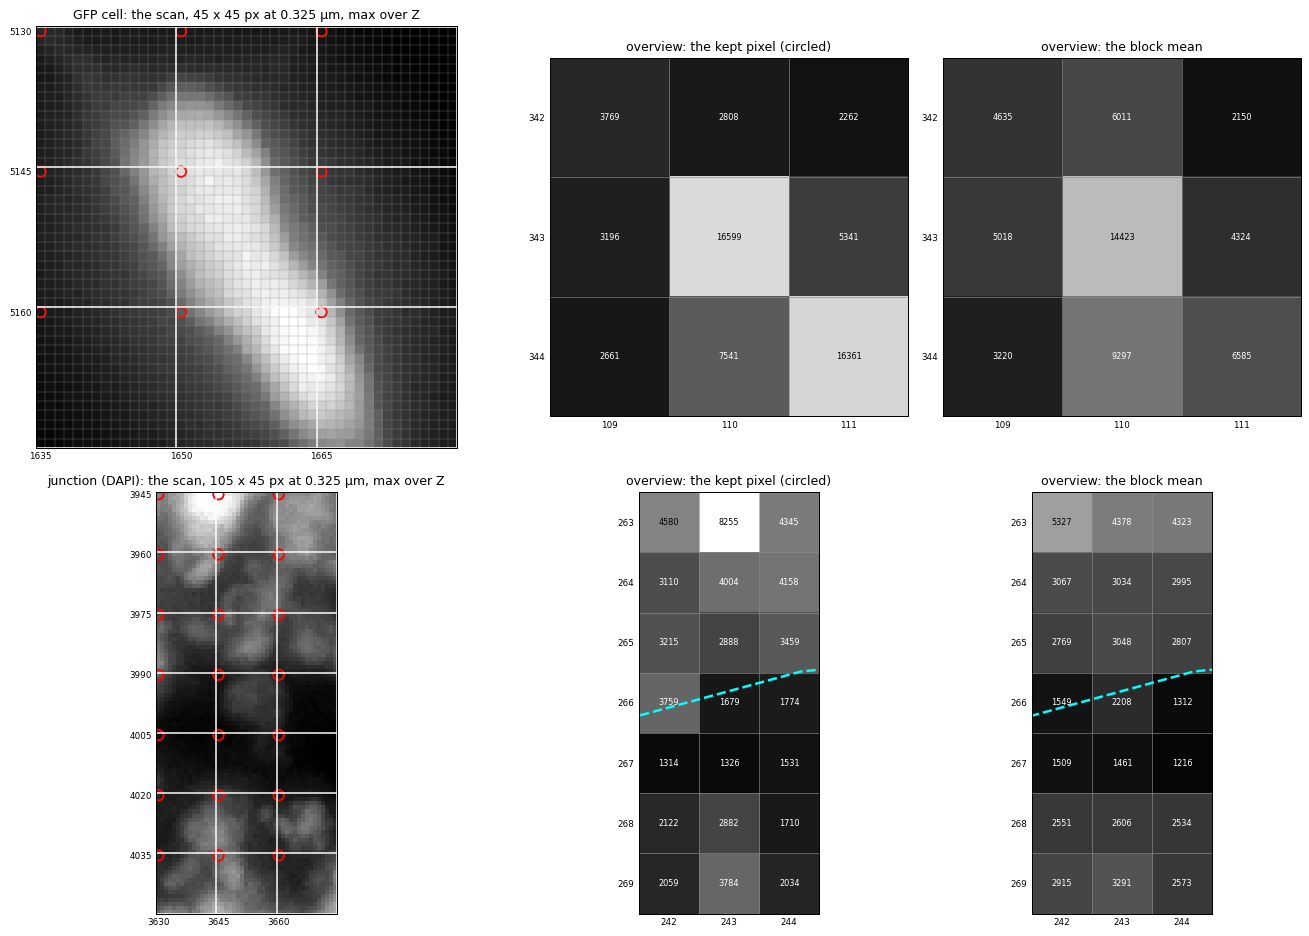

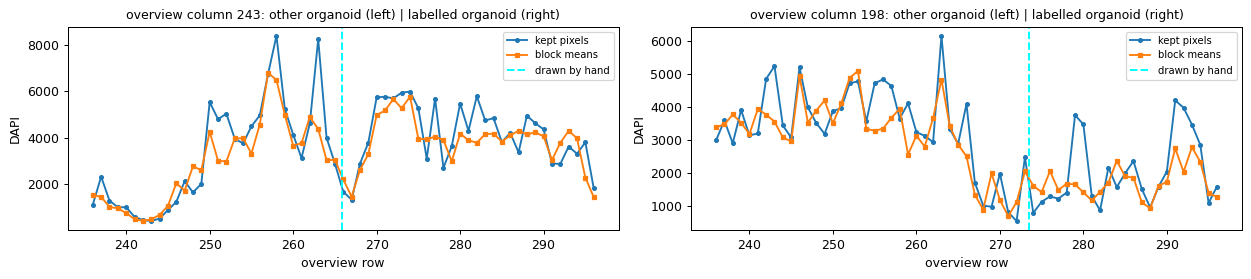

In [3]:
overview, options, um, step = W.overview, W.options, W.um, W.overview.step
channels = overview.channels
nuclear, label, other = overview.nuclear, overview.label, overview.other
manual_line_um = W.manual_line
print(f"full resolution {overview.shape_yx[0]} x {overview.shape_yx[1]} px at {overview.voxel_yx[0]} µm; "
      f"overview {channels.shape[1]} x {channels.shape[2]} px at {um} µm; step {step}")
print(f"channels: nuclear {overview.names[nuclear]}, labelled {overview.names[label]}, other {overview.names[other]}")

RAW = DATA / f"{WORKED}.ome.tiff"
specs = loaders.load_path(RAW)


def read_window(k, r0, c0, h, w):
    """Channel *k* of the scan, rows r0..r0+h and columns c0..c0+w at full resolution: every plane, (Z, h, w)."""
    array = specs[k].data[0] if getattr(specs[k], "multiscale", False) else specs[k].data
    block = np.asarray(array[..., r0:r0 + h, c0:c0 + w], dtype=np.float32)
    return block.reshape((-1, h, w))


# A GFP cell: the brightest kept GFP pixel well inside the labelled half.
inner = ndimage.binary_erosion(W.halves == 1, iterations=5)
r, c = np.unravel_index(np.argmax(np.where(inner, channels[label], 0)), inner.shape)
cell_blocks = (r - 1, c - 1, 3, 3)                         # 3 x 3 overview pixels round it
# The junction: 7 x 3 overview pixels across the hand-drawn line, in the middle of the section.
along = jt.dense(manual_line_um) / um
lr, lc = np.round(along[len(along) // 2]).astype(int)
line_blocks = (lr - 3, lc - 1, 7, 3)

fig, axes = plt.subplots(2, 3, figsize=(15, 10.5), gridspec_kw={"width_ratios": [1.5, 1, 1]})
for row, (k, (br, bc, bh, bw), name) in enumerate(((label, cell_blocks, "GFP cell"),
                                                   (nuclear, line_blocks, "junction (DAPI)"))):
    stack = read_window(k, br * step, bc * step, bh * step, bw * step)
    flat = stack.max(axis=0)                                # max over Z
    kept = flat[::step, ::step]
    assert np.array_equal(kept, channels[k][br:br + bh, bc:bc + bw])       # the overview's own pixels
    means = np.max([jn._block_mean(plane, step, (bh, bw)) for plane in stack], axis=0)
    if k == nuclear:
        assert np.allclose(means, overview.nuclear_mean[br:br + bh, bc:bc + bw])
    origin = (br * step, bc * step)
    lo, hi = np.percentile(flat, (1, 99.5))
    pixels(axes[row, 0], flat, f"{name}: the scan, {bh * step} x {bw * step} px at 0.325 µm, max over Z",
           origin=origin, vmin=lo, vmax=hi, every=step)
    for j in range(bw + 1):
        axes[row, 0].axvline(origin[1] + j * step - 0.5, color="white", lw=1.2)
    for i in range(bh + 1):
        axes[row, 0].axhline(origin[0] + i * step - 0.5, color="white", lw=1.2)
    ki, kj = np.mgrid[0:bh, 0:bw] * step
    axes[row, 0].scatter(kj.ravel() + origin[1], ki.ravel() + origin[0], s=70, facecolors="none", edgecolors="red", lw=1.5)
    pixels(axes[row, 1], kept, "overview: the kept pixel (circled)", fmt=".0f", origin=(br, bc), vmin=lo, vmax=hi, every=1)
    pixels(axes[row, 2], means, "overview: the block mean", fmt=".0f", origin=(br, bc), vmin=lo, vmax=hi, every=1)
for ax in axes[1, 1:]:
    hand(ax, W, lw=2)
    limits(ax, line_blocks)
plt.tight_layout()

# Across the junction: the hand-drawn line runs left to right here, so a column crosses it.
fig, axes = plt.subplots(1, 2, figsize=(14, 3.2))
order = np.argsort(along[:, 1])
rows = np.arange(lr - 30, lr + 31)
for ax, col in zip(axes, (lc, int(np.round(along[len(along) // 3, 1])))):
    ax.plot(rows, channels[nuclear][rows, col], "o-", ms=3, label="kept pixels")
    ax.plot(rows, overview.nuclear_mean[rows, col], "s-", ms=3, label="block means")
    ax.axvline(np.interp(col, along[order, 1], along[order, 0]), **HAND, label="drawn by hand")
    ax.set_xlabel("overview row"); ax.set_ylabel("DAPI"); ax.legend(fontsize=8)
    ax.set_title(f"overview column {col}: other organoid (left) | labelled organoid (right)")
plt.tight_layout()
loaders.release(RAW)

## Step 1 — the tissue mask, operation by operation

`tissue_mask(nuclear, valid, um, others)` finds the tissue in **every channel**, not only DAPI (`JunctionOptions.tissue_all_channels`, on by default since 22 October). An organoid whose nuclear stain is faint, common in one of a pair, is still bright in its own label or its autofluorescence; with DAPI alone it would be dropped, and the junction would stop where the mask does. `find_junction` passes the other channels as `others`, and so does this cell.

1. **`valid`**: pixels where every channel is above zero. Stitching pads with exact zeros, and those must not count as background.
2. **Per channel** (`_above_background`):
   - **Gaussian smoothing, σ = 10 µm ≈ 2 pixels.** Each pixel becomes a weighted mean of its neighbours, with the weights printed below. This merges single nuclei (or cells) into a continuous tissue signal.
   - **Threshold.** Otsu's method splits the smoothed values in two (the split that makes the two groups as tight as possible). From each group its *median* is taken, and the cut is put a **fifth of the way** from the background median to the tissue median. A dim organoid sits well above that; it may sit below Otsu's midpoint.
3. **Union**: a pixel is tissue if it stands above the slide in **any** channel.
4. **Opening** with a disc of radius 2 pixels (10 µm): a pixel stays only if the disc, placed somewhere covering it, fits entirely inside the mask. Removes specks and thin spurs. (Red: removed.)
5. **Closing** with a disc of radius 3 pixels (15 µm): the mask is grown by the disc, then shrunk by it. A gap or notch narrower than the disc is filled by the growing and not reopened by the shrinking. (Green: added.)
6. **Pieces**: connected groups of pixels (touching by a side). Any piece smaller than a tenth of the largest is debris and is dropped; a second organoid lying apart would be about as big as the first and is kept.

`filled` is the same mask with every hole filled (a hole: background pixels that cannot reach the image border through background). The cut of step 5 is made in `filled`.

σ = 2.05 px; the centre pixel keeps 0.038 of itself, the 11 x 11 square holds 1.000


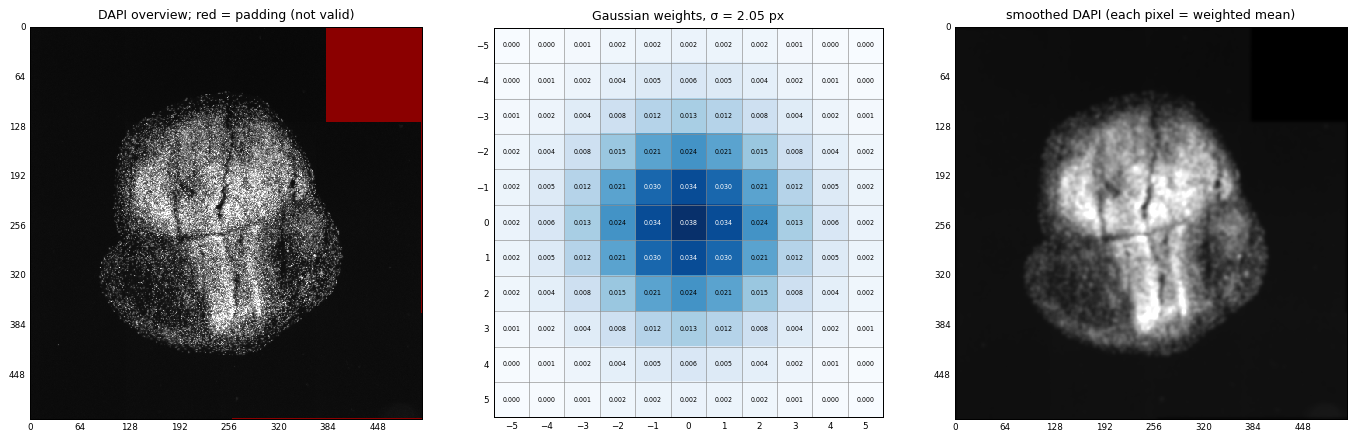

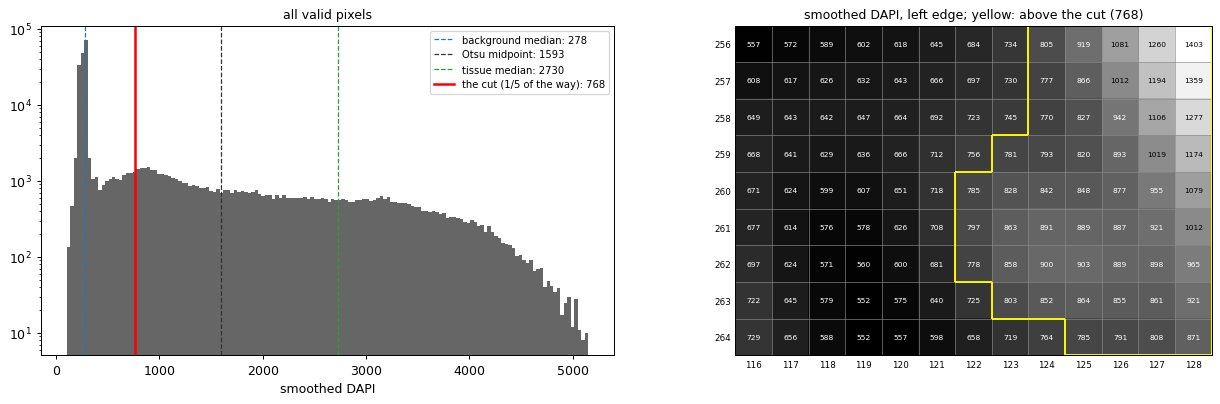

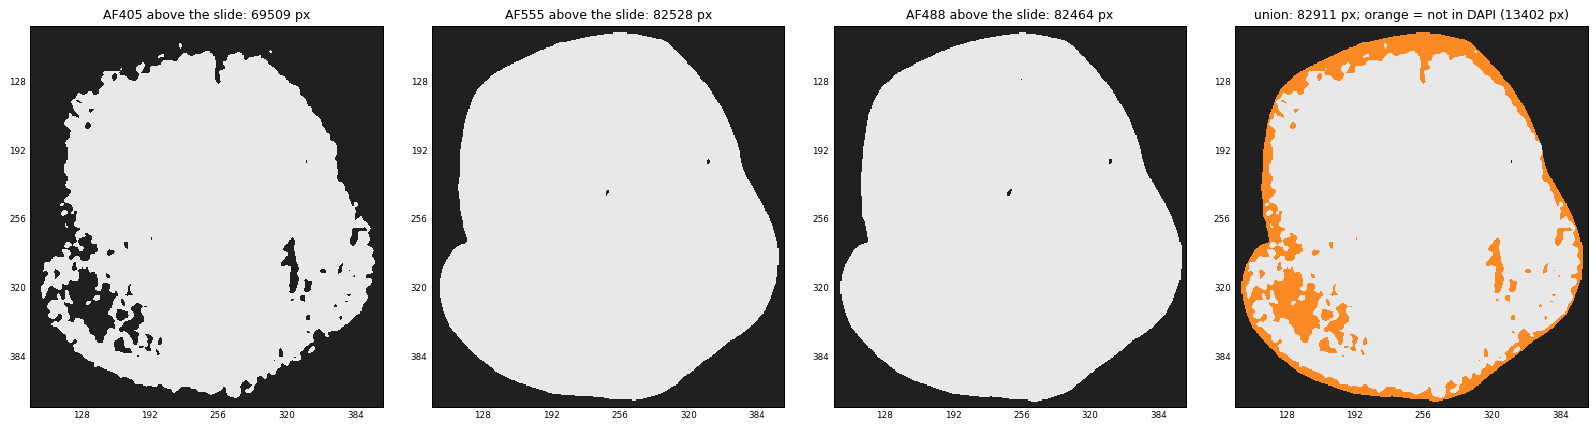

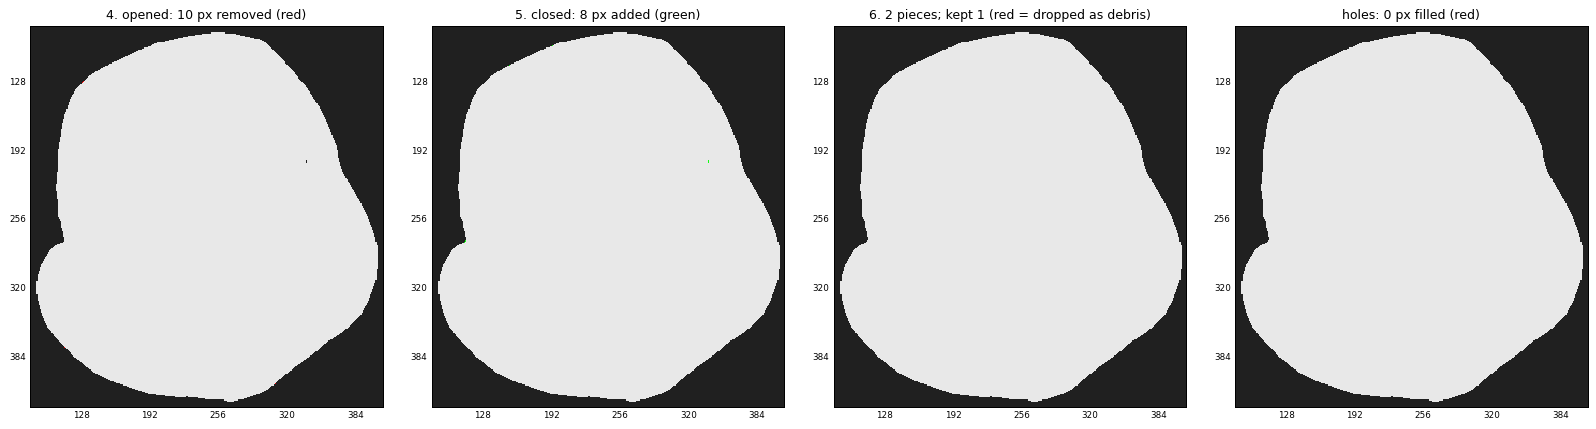

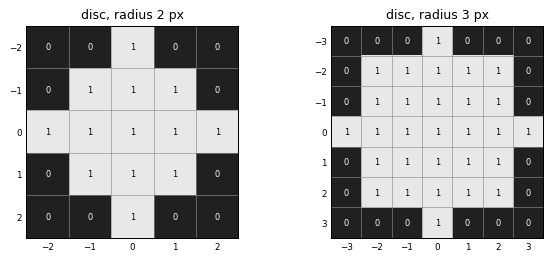

In [4]:
from skimage.filters import threshold_otsu

valid = (channels > 0).all(axis=0)


def above_background(plane):
    """jn._above_background, line by line: the smoothed plane, its levels and the mask."""
    smooth = ndimage.gaussian_filter(np.asarray(plane, dtype=np.float32), 10.0 / um)
    values = smooth[valid]
    midpoint = threshold_otsu(values)
    below, above = values[values < midpoint], values[values >= midpoint]
    background_level, tissue_level = float(np.median(below)), float(np.median(above))
    cut = background_level + 0.2 * (tissue_level - background_level)
    return SimpleNamespace(smooth=smooth, values=values, midpoint=midpoint, background=background_level,
                           tissue=tissue_level, cut=cut, mask=(smooth > cut) & valid)


per_channel = {k: above_background(channels[k]) for k in range(len(channels))}
for k, found in per_channel.items():
    assert np.array_equal(found.mask, jn._above_background(channels[k], valid, um))
order_k = [nuclear] + [k for k in range(len(channels)) if k != nuclear]     # DAPI first, as tissue_mask does
raw = per_channel[nuclear].mask.copy()
for k in order_k[1:]:
    raw |= per_channel[k].mask
opened = ndimage.binary_opening(raw, jn._disk(10.0 / um))
closed = ndimage.binary_closing(opened, jn._disk(15.0 / um))
pieces, count = ndimage.label(closed)
sizes = np.bincount(pieces.ravel())[1:]
keep = np.flatnonzero(sizes >= 0.1 * sizes.max()) + 1
tissue = np.isin(pieces, keep)
others = jn._others(channels, nuclear, options.tissue_all_channels)
assert np.array_equal(tissue, jn.tissue_mask(channels[nuclear], valid, um, others))   # the same, pixel for pixel
assert np.array_equal(tissue, W.result.tissue)                                       # and what find_junction used
filled = ndimage.binary_fill_holes(tissue)
dapi = per_channel[nuclear]
view = W.view

delta = np.zeros((11, 11)); delta[5, 5] = 1
kernel = ndimage.gaussian_filter(delta, 10.0 / um)
print(f"σ = {10.0 / um:.2f} px; the centre pixel keeps {kernel[5, 5]:.3f} of itself, the 11 x 11 square holds {kernel.sum():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.2, 1, 1.2]})
pixels(axes[0], channels[nuclear], "DAPI overview; red = padding (not valid)", vmax=np.percentile(channels[nuclear], 99.5))
tint(axes[0], ~valid, "red")
pixels(axes[1], kernel, "Gaussian weights, σ = 2.05 px", fmt=".3f", cmap="Blues", origin=(-5, -5), every=1, fontsize=5)
pixels(axes[2], dapi.smooth, "smoothed DAPI (each pixel = weighted mean)", vmax=np.percentile(dapi.smooth, 99.5))
plt.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].hist(dapi.values, bins=150, color="0.4")
for x, name, colour in ((dapi.background, "background median", "tab:blue"), (dapi.midpoint, "Otsu midpoint", "0.2"),
                        (dapi.tissue, "tissue median", "tab:green"), (dapi.cut, "the cut (1/5 of the way)", "red")):
    axes[0].axvline(x, color=colour, lw=2 if colour == "red" else 1, ls="-" if colour == "red" else "--", label=f"{name}: {x:.0f}")
axes[0].set_yscale("log"); axes[0].legend(fontsize=8); axes[0].set_xlabel("smoothed DAPI"); axes[0].set_title("all valid pixels")
mid_row = int(np.mean(np.nonzero(filled)[0]))
edge_col = int(np.flatnonzero(dapi.mask[mid_row])[0])
z = (mid_row - 4, edge_col - 6, 9, 13)                       # the left edge of the tissue
pixels(axes[1], crop(dapi.smooth, *z), f"smoothed DAPI, left edge; yellow: above the cut ({dapi.cut:.0f})",
       fmt=".0f", origin=z[:2], every=1, fontsize=6)
edges(axes[1], crop(dapi.mask, *z), origin=z[:2])
plt.tight_layout()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, k in zip(axes, order_k):
    pixels(ax, per_channel[k].mask, f"{overview.names[k]} above the slide: {int(per_channel[k].mask.sum())} px", cmap=MASK)
    limits(ax, view)
pixels(axes[3], raw, f"union: {int(raw.sum())} px; orange = not in DAPI ({int((raw & ~dapi.mask).sum())} px)", cmap=MASK)
tint(axes[3], raw & ~dapi.mask, "tab:orange", 0.9)
limits(axes[3], view)
plt.tight_layout()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
pixels(axes[0], opened, f"4. opened: {int((raw & ~opened).sum())} px removed (red)", cmap=MASK)
tint(axes[0], raw & ~opened, "red", 0.9)
pixels(axes[1], closed, f"5. closed: {int((closed & ~opened).sum())} px added (green)", cmap=MASK)
tint(axes[1], closed & ~opened, "lime", 0.9)
pixels(axes[2], tissue, f"6. {count} pieces; kept {len(keep)} (red = dropped as debris)", cmap=MASK)
tint(axes[2], closed & ~tissue, "red", 0.9)
pixels(axes[3], tissue.astype(int) + filled, f"holes: {int((filled & ~tissue).sum())} px filled (red)",
       cmap=ListedColormap(["#202020", "#d1495b", "#e8e8e8"]))
for ax in axes:
    limits(ax, view)
plt.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, radius in zip(axes, (10.0 / um, 15.0 / um)):
    disc = jn._disk(radius)
    pixels(ax, disc, f"disc, radius {max(int(round(radius)), 1)} px", cmap=MASK, fmt=".0f",
           origin=(-(disc.shape[0] // 2), -(disc.shape[1] // 2)), every=1)
plt.tight_layout()

**On the failed section** the same operations leave **holes** inside the tissue: the open tears. In `filled` they are filled in, so for the cut of step 5 a tear is part of the section, and, being empty of nuclei, the darkest part of it.

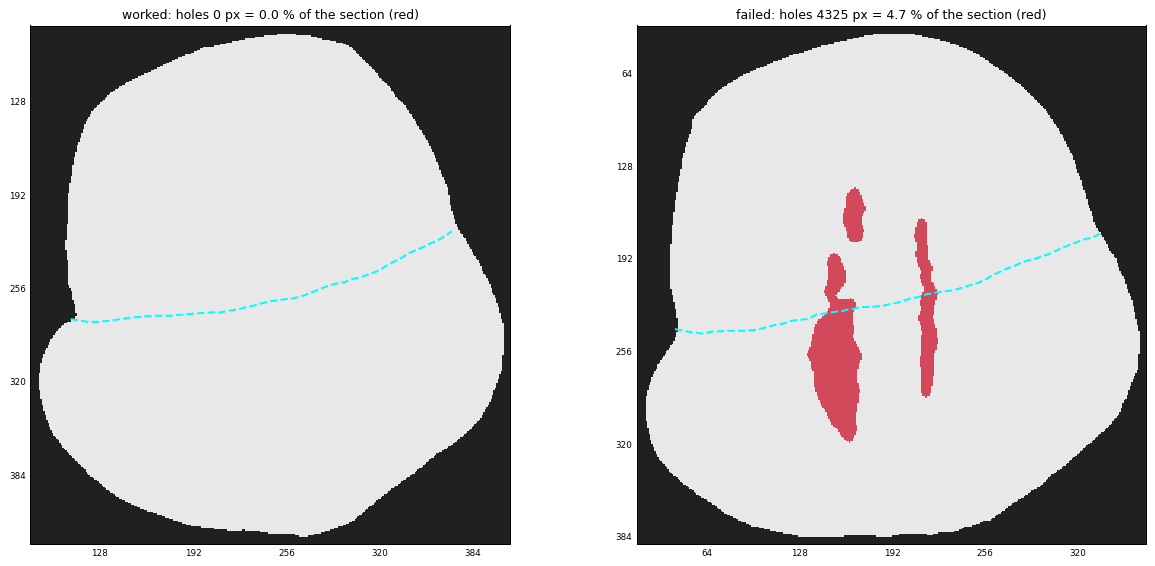

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, case, tag in zip(axes, (W, F), ("worked", "failed")):
    holes = case.filled & ~case.tissue
    pixels(ax, case.tissue.astype(int) + case.filled,
           f"{tag}: holes {int(holes.sum())} px = {100 * holes.sum() / case.filled.sum():.1f} % of the section (red)",
           cmap=ListedColormap(["#202020", "#d1495b", "#e8e8e8"]))
    hand(ax, case)
    limits(ax, case.view)
plt.tight_layout()

## Step 2 — labelled cells: each pixel against the median of its neighbours

`cell_density(channel, tissue, filled, um)`:

1. **Local median** over a square of `size` pixels, `size = round(median_um / um)` made odd (`median_um` = 45 µm by default): here **9 × 9**. With `use_median=False` this step and the next are skipped and the channel itself is blurred; the last panel shows what that does. The median of 81 values is the 41st largest; a cell covers a few of them, so the median ignores it and reports the background around it.
2. **Prominence** = pixel − local median, negatives set to 0. Below: the same operation on a **cell** (a sharp point: large prominence) and on the **brightest diffuse patch** of the section, the brightest local median with no cell within 9 pixels (bright, but its neighbours are just as bright: little prominence).
3. Divided by the 99.5th percentile of the prominence inside the tissue and clipped to 0–1, so the brightest half-percent of points all count as 1 and the map does not depend on the channel's brightness.
4. **Normalised blur** over 100 µm (σ ≈ 20 px): `amount` = blur of the prominence with everything outside the tissue set to 0; `weight` = blur of the tissue mask itself (the share of the kernel that is on tissue); density = `amount / weight`. At the edge of the section half the kernel is off tissue, so `amount` halves although the cells do not; `weight` halves too and the ratio stays put. The profile below shows that along one row.

median window 9 x 9 px; 99.5th percentile of the prominence: 728


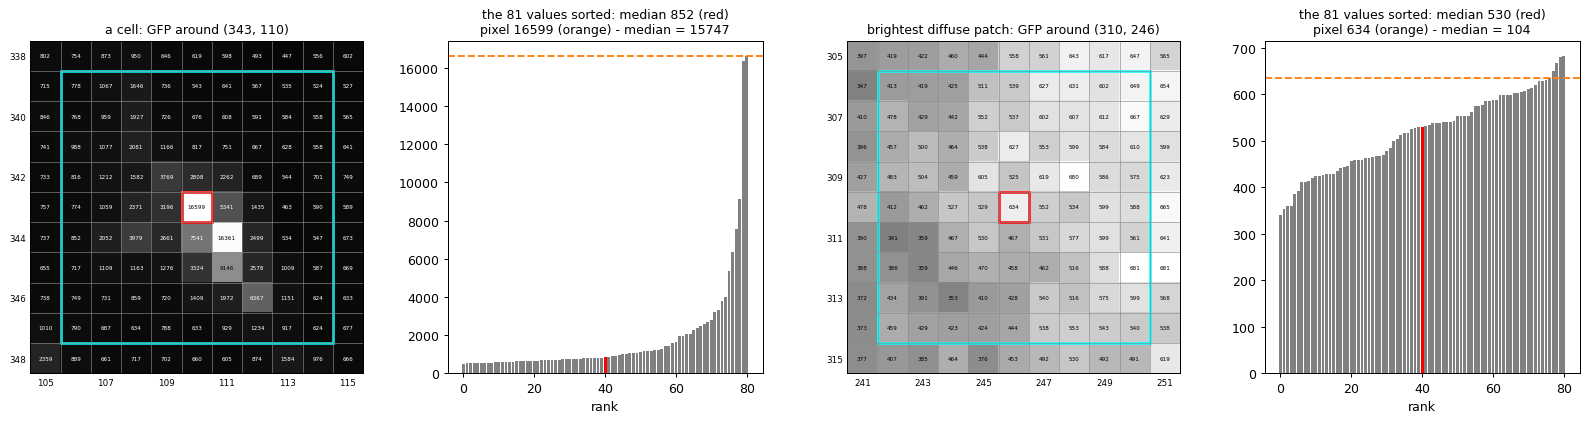

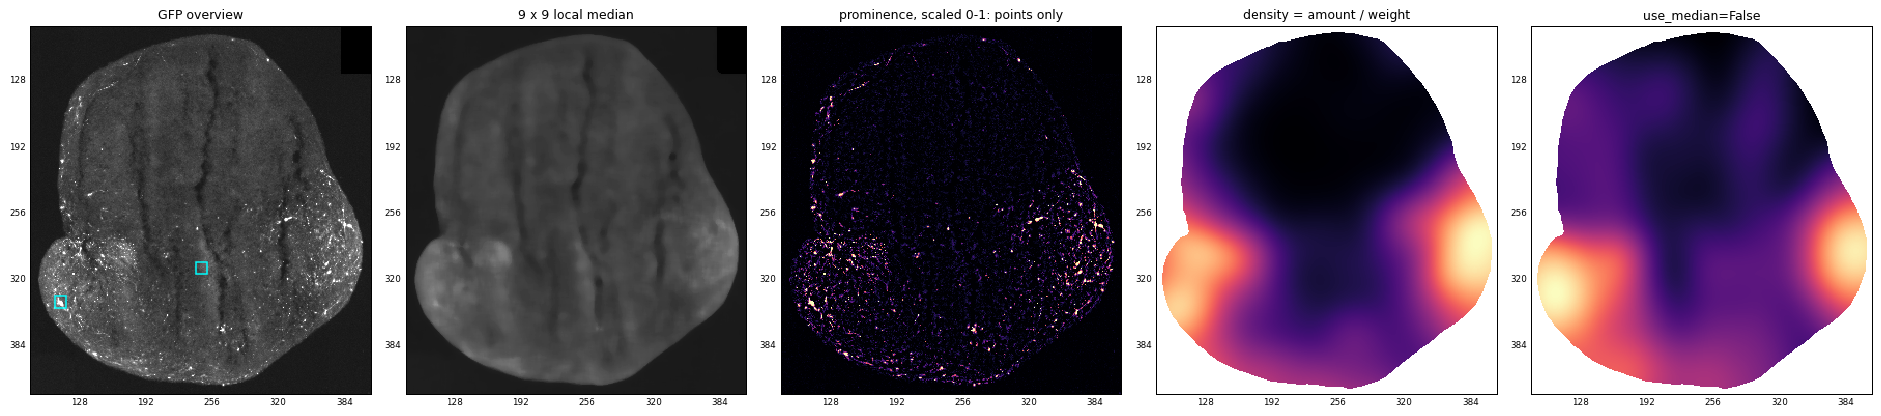

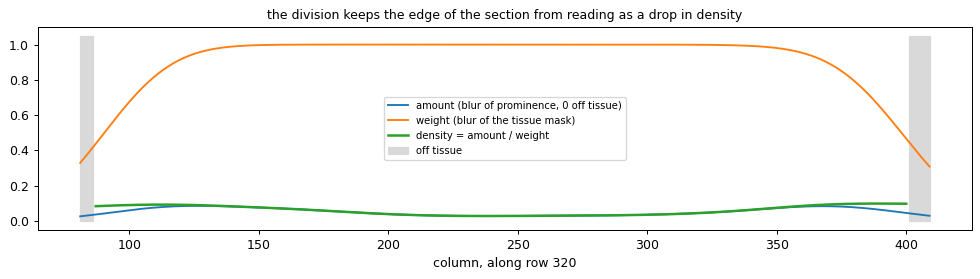

In [6]:
gfp_plane = channels[label]
size = max(3, int(round(options.median_um / um)) | 1)
local_median = ndimage.median_filter(gfp_plane, size)
prominence = np.clip(gfp_plane - local_median, 0, None)
top = float(np.percentile(prominence[tissue], 99.5))
scaled = np.clip(prominence / (top + 1e-6), 0, 1)
sigma = 100.0 / um
amount = ndimage.gaussian_filter(np.where(tissue, scaled, 0).astype(np.float32), sigma)
weight = ndimage.gaussian_filter(tissue.astype(np.float32), sigma)
density = np.where(filled, amount / np.maximum(weight, 1e-3), 0).astype(np.float32)
assert np.array_equal(density, jn.cell_density(gfp_plane, tissue, filled, um))
assert np.array_equal(density, W.density)
assert np.array_equal(prominence, jn.cell_prominence(gfp_plane, um))
density_no_median = jn.cell_density(gfp_plane, tissue, filled, um, median=False)
print(f"median window {size} x {size} px; 99.5th percentile of the prominence: {top:.0f}")

inner = ndimage.binary_erosion(tissue, iterations=8)
cell_rc = np.unravel_index(np.argmax(np.where(inner & (W.halves == 1), prominence, 0)), prominence.shape)
quiet = ndimage.maximum_filter(prominence, 2 * size + 1) < np.percentile(prominence[tissue], 95)   # no cell nearby
cloud_rc = np.unravel_index(np.argmax(np.where(inner & quiet, local_median, 0)), prominence.shape)
half = size // 2
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.2, 1, 1.2, 1]})
for ax_pair, (r, c), name in ((axes[:2], cell_rc, "a cell"), (axes[2:], cloud_rc, "brightest diffuse patch")):
    z = (r - half - 1, c - half - 1, size + 2, size + 2)
    pixels(ax_pair[0], crop(gfp_plane, *z), f"{name}: GFP around ({r}, {c})", fmt=".0f", origin=z[:2], every=2,
           vmin=0, vmax=crop(gfp_plane, *z).max(), fontsize=4.5)
    ax_pair[0].add_patch(Rectangle((c - half - 0.5, r - half - 0.5), size, size, fill=False, ec="cyan", lw=2))
    ax_pair[0].add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec="red", lw=2))
    hood = np.sort(crop(gfp_plane, r - half, c - half, size, size).ravel())
    middle = len(hood) // 2
    ax_pair[1].bar(range(len(hood)), hood, color=["red" if k == middle else "0.5" for k in range(len(hood))])
    ax_pair[1].axhline(gfp_plane[r, c], color="tab:orange", ls="--")
    ax_pair[1].set_title(f"the {len(hood)} values sorted: median {hood[middle]:.0f} (red)\n"
                         f"pixel {gfp_plane[r, c]:.0f} (orange) - median = {prominence[r, c]:.0f}")
    ax_pair[1].set_xlabel("rank")
plt.tight_layout()

fig, axes = plt.subplots(1, 5, figsize=(21, 4.4))
pixels(axes[0], gfp_plane, "GFP overview", vmax=np.percentile(gfp_plane[tissue], 99.7))
pixels(axes[1], local_median, f"{size} x {size} local median", vmax=np.percentile(gfp_plane[tissue], 99.7))
pixels(axes[2], scaled, "prominence, scaled 0-1: points only", cmap="magma")
pixels(axes[3], np.where(filled, density, np.nan), "density = amount / weight", cmap="magma")
pixels(axes[4], np.where(filled, density_no_median, np.nan), "use_median=False", cmap="magma")
for (r, c) in (cell_rc, cloud_rc):
    axes[0].add_patch(Rectangle((c - half - 1.5, r - half - 1.5), size + 2, size + 2, fill=False, ec="cyan", lw=1.2))
for ax in axes:
    limits(ax, view)
plt.tight_layout()

row = int(np.mean(np.nonzero(filled)[0])) + 60
fig, ax = plt.subplots(figsize=(11, 3.2))
cols = np.arange(view[1], view[1] + view[3])
ax.plot(cols, amount[row, cols], "-", label="amount (blur of prominence, 0 off tissue)")
ax.plot(cols, weight[row, cols], "-", label="weight (blur of the tissue mask)")
ax.plot(cols, np.where(filled[row, cols], density[row, cols], np.nan), "-", lw=2, label="density = amount / weight")
ax.fill_between(cols, 0, 1.05 * weight[row].max(), where=~filled[row, cols], color="0.85", step="mid", label="off tissue")
ax.set_xlabel(f"column, along row {row}"); ax.legend(fontsize=8)
ax.set_title("the division keeps the edge of the section from reading as a drop in density")
plt.tight_layout()

### Does a channel hold cells at all? (`has_cells`)

`cell_density` scales a channel by its own brightest points, so a channel holding only noise would be stretched into a map that looks as full as a real one. `has_cells` asks first. Per pixel it takes the same *pixel − local median* (without clipping), then compares the **99.9th percentile** (the brightest points) with the **robust spread** of all of them (median absolute deviation × 1.4826, which equals the standard deviation for pure noise). Cells stand far above the spread; noise reaches about 3. The cut is 6.

Below: GFP and AF555 measured over the tissue, and, for comparison, the same GFP channel measured over **bare slide** next to the section: a real part of the scan with no cells in it.

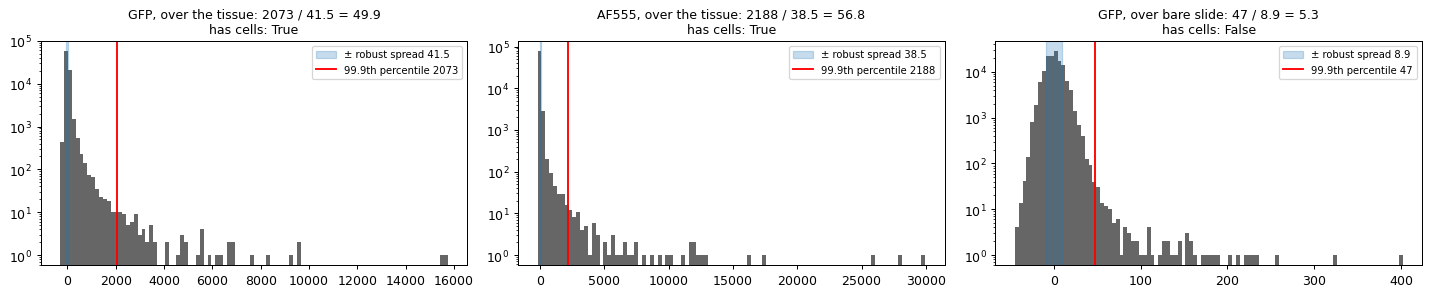

In [7]:
slide = valid & ~ndimage.binary_dilation(filled, iterations=20)    # bare slide, at least 100 µm from the section
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, (name, plane, where) in zip(axes, (("GFP, over the tissue", gfp_plane, tissue),
                                           ("AF555, over the tissue", channels[other], tissue),
                                           ("GFP, over bare slide", gfp_plane, slide))):
    over = (plane - ndimage.median_filter(plane, size))[where]
    spread = float(np.median(np.abs(over - np.median(over)))) * 1.4826
    brightest = float(np.percentile(over, 99.9))
    verdict = jn.has_cells(plane, where, um)
    ax.hist(over, bins=100, color="0.4")
    ax.axvspan(-spread, spread, color="tab:blue", alpha=0.25, label=f"± robust spread {spread:.1f}")
    ax.axvline(brightest, color="red", label=f"99.9th percentile {brightest:.0f}")
    ax.set_yscale("log"); ax.legend(fontsize=8)
    ax.set_title(f"{name}: {brightest:.0f} / {spread:.1f} = {brightest / spread:.1f}\nhas cells: {verdict}")
plt.tight_layout()

## Step 3 — the seeds, mask by mask

`find_seeds(filled, density, other_density)`, in order:

1. **Normalise** each density: 0 at its 10th percentile in the tissue, 1 at its 98th, clipped.
2. **Labelled core**: pixels above **0.5**, and of those only the **largest piece** (pixels touching by a side). Smaller patches above 0.5 elsewhere are ignored.
3. **Distance through the tissue** from that core (`_through_tissue`). A walk from pixel to pixel through `filled`, in any of 8 directions, each step counting 1, diagonal or not, so it is a count of steps rather than µm (the start pixels count 1 themselves; to save time the walk starts from every 7th seed pixel). Off tissue a step costs 10⁹, so the walk goes round a notch in the outline instead of across it. Holes are no obstacle: the walk runs through `filled`, where they are filled in. The small U of tissue drawn after the section is an **illustration** of the walk, not a sample: the top of the right arm is 7 to 10 steps away in a straight line, 15 round the bottom of the U.
4. **Other core**: pixels where the *other* label (AF555) is above 0.5, **and** not in the labelled core, **and** where the other label (normalised) outweighs the labelled one. Largest piece. Used if it covers at least 2 % of the tissue.
5. **Pull back** (`_far_part`): of each core, keep the pixels further from the other seed than **half** of the core's furthest pixel, then the largest piece. Both seeds then start well inside their organoid.

The old second-seed rule (used when the other channel holds no cells) is drawn last: tissue further than half the furthest distance from the labelled core, where the labelled density is below 0.2.

Look at the first panel: on this section the GFP density has **two** dense patches above 0.5, one at each end of the labelled organoid. Only the larger becomes the labelled seed.

GFP pieces above 0.5: 2, sizes [8946, 7648] px
second seed: dense core of the other organoid's label;  other core covers 7.0 % of the tissue (needs 2 %)


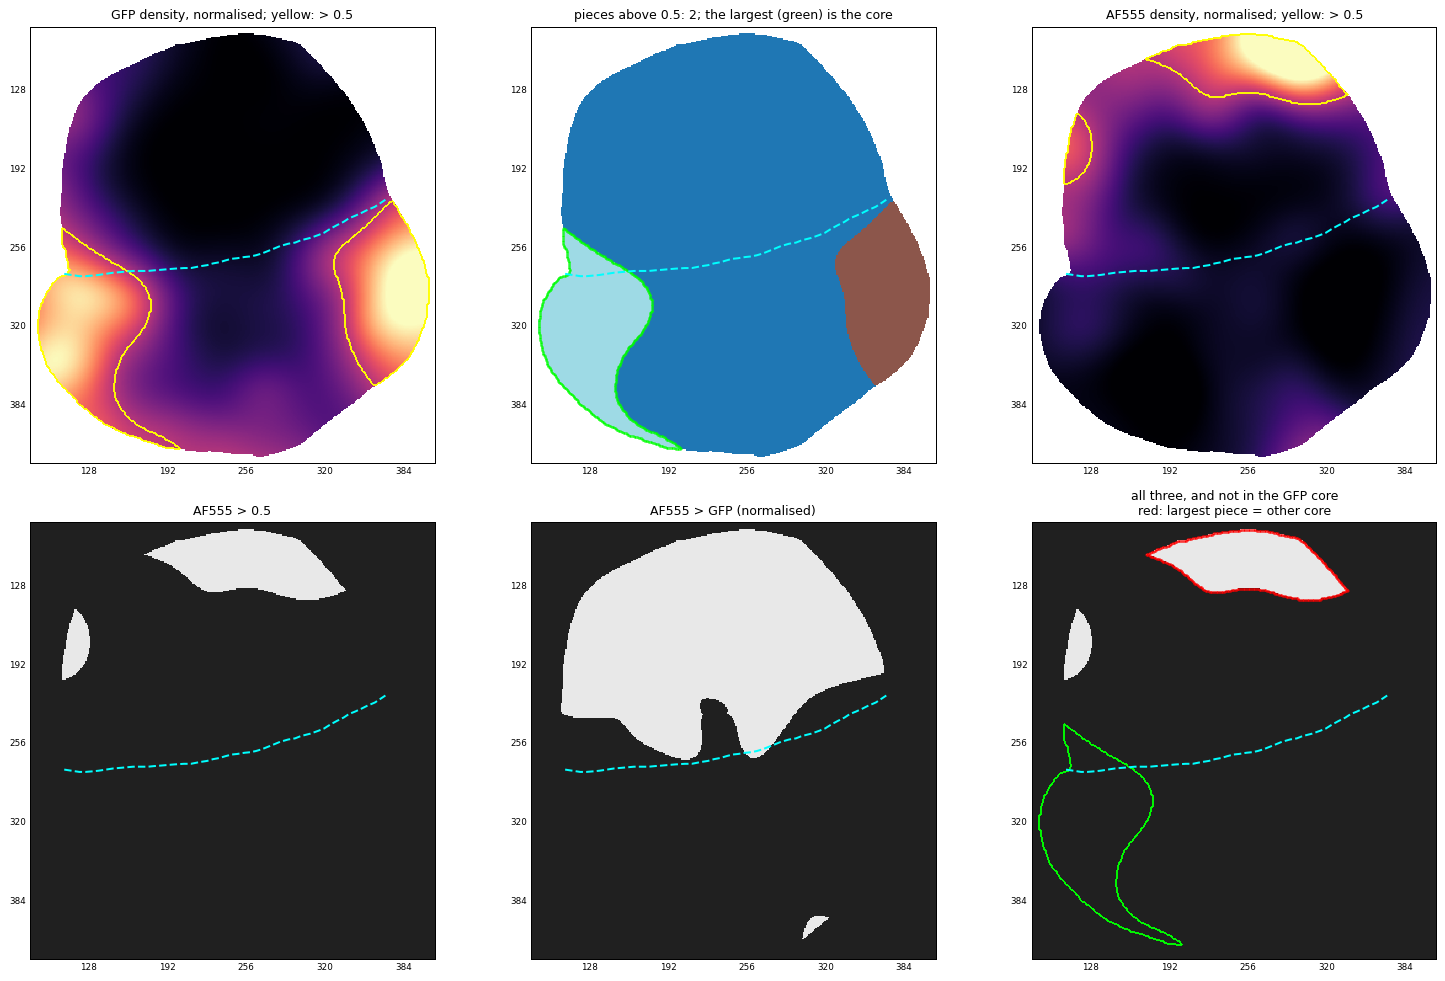

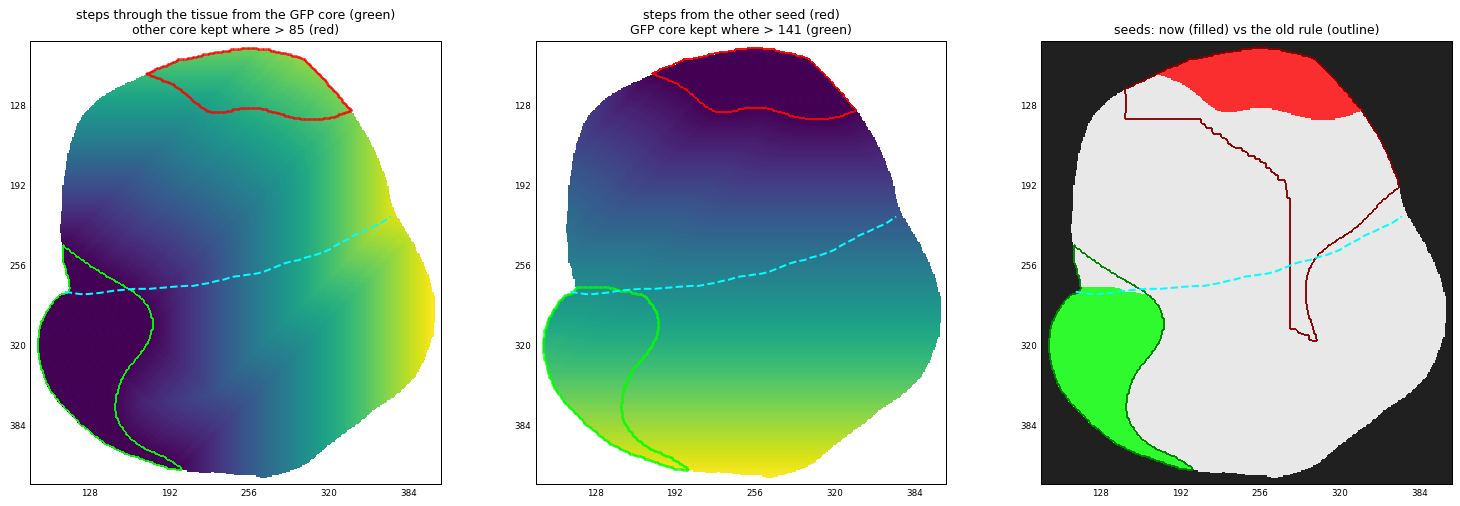

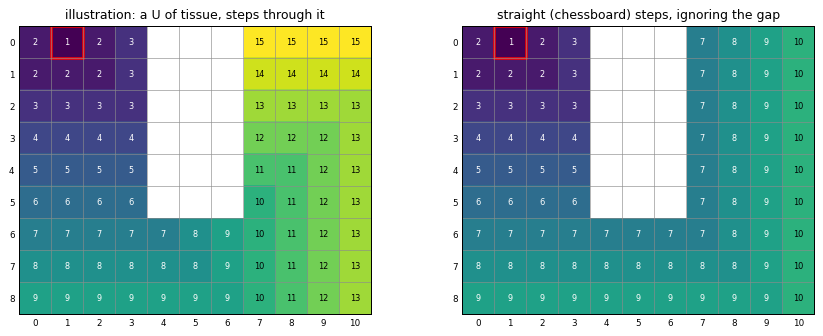

In [8]:
other_plane = channels[other]
other_density = jn.cell_density(other_plane, tissue, filled, um) if jn.has_cells(other_plane, tissue, um) else None
normal = jn._normalised(density, filled)
other_normal = jn._normalised(other_density, filled)

hot_all = (normal > 0.5) & filled
hot = jn._largest(hot_all)
from_hot = jn._through_tissue(filled, hot)
conditions = ((other_normal > 0.5) & filled, ~hot, other_normal > normal)
core_all = conditions[0] & conditions[1] & conditions[2]
core = jn._largest(core_all)
share = core.sum() / filled.sum()
cold = jn._far_part(core, from_hot)
from_cold = jn._through_tissue(filled, cold)
hot_seed = jn._far_part(hot, from_cold)
found = jn.find_seeds(filled, density, other_density)
assert np.array_equal(found[0], hot_seed) and np.array_equal(found[1], cold)
assert np.array_equal(hot_seed, W.hot) and np.array_equal(cold, W.cold)
hot_pieces, n = ndimage.label(hot_all)
print(f"GFP pieces above 0.5: {n}, sizes {sorted(np.bincount(hot_pieces.ravel())[1:].tolist(), reverse=True)} px")
print(f"second seed: {found[2]};  other core covers {100 * share:.1f} % of the tissue (needs 2 %)")

fig, axes = plt.subplots(2, 3, figsize=(17, 11))
pixels(axes[0, 0], np.where(filled, normal, np.nan), "GFP density, normalised; yellow: > 0.5", cmap="magma", vmin=0, vmax=1)
edges(axes[0, 0], hot_all)
pixels(axes[0, 1], np.where(filled, hot_pieces, np.nan), f"pieces above 0.5: {n}; the largest (green) is the core", cmap="tab20")
edges(axes[0, 1], hot, "lime", 2)
pixels(axes[0, 2], np.where(filled, other_normal, np.nan), "AF555 density, normalised; yellow: > 0.5", cmap="magma", vmin=0, vmax=1)
edges(axes[0, 2], conditions[0])
for ax, mask, title in zip(axes[1], (conditions[0], conditions[2], core_all),
                           ("AF555 > 0.5", "AF555 > GFP (normalised)", "all three, and not in the GFP core")):
    pixels(ax, mask & filled, title, cmap=MASK)
edges(axes[1, 2], hot, "lime", 1.5)
edges(axes[1, 2], core, "red", 2)
axes[1, 2].set_title(axes[1, 2].get_title() + "\nred: largest piece = other core")
for ax in axes.ravel():
    hand(ax, W)
    limits(ax, view)
plt.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
away = np.where(core, from_hot, 0.0)
pixels(axes[0], np.where(filled, from_hot, np.nan), f"steps through the tissue from the GFP core (green)\nother core kept where > {0.5 * away.max():.0f} (red)",
       cmap="viridis")
edges(axes[0], hot, "lime", 1.5); edges(axes[0], cold, "red", 2)
away = np.where(hot, from_cold, 0.0)
pixels(axes[1], np.where(filled, from_cold, np.nan), f"steps from the other seed (red)\nGFP core kept where > {0.5 * away.max():.0f} (green)",
       cmap="viridis")
edges(axes[1], cold, "red", 1.5); edges(axes[1], hot_seed, "lime", 2)
old = jn.find_seeds(filled, density, None)
pixels(axes[2], filled, "seeds: now (filled) vs the old rule (outline)", cmap=MASK)
tint(axes[2], hot_seed, "lime", 0.8); tint(axes[2], cold, "red", 0.8)
edges(axes[2], old[0], "green", 1.5); edges(axes[2], old[1], "darkred", 1.5)
for ax in axes:
    hand(ax, W)
    limits(ax, view)
plt.tight_layout()

# An illustration of the walk, not a sample: a small U of tissue, from one pixel at the tip of its left arm.
u_shape = np.ones((9, 11), bool)
u_shape[:6, 4:7] = False
u_start = np.zeros_like(u_shape); u_start[0, 1] = True
u_steps = jn._through_tissue(u_shape, u_start)
u_straight = ndimage.distance_transform_cdt(~u_start, metric="chessboard") + 1.0
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, values, title in ((axes[0], u_steps, "illustration: a U of tissue, steps through it"),
                          (axes[1], u_straight, "straight (chessboard) steps, ignoring the gap")):
    pixels(ax, np.where(u_shape, values, np.nan), title, fmt=".0f", cmap="viridis", vmin=1, vmax=u_steps.max(), every=1)
    ax.add_patch(Rectangle((0.5, -0.5), 1, 1, fill=False, ec="red", lw=2))
plt.tight_layout()

**On the failed section** the same rule does the same thing, but the result matters more. Again the GFP density has more than one patch above 0.5 (outlined in cyan, size in pixels); the labelled seed (green) is the largest, the lower-left corner of the labelled organoid, and the patch at its right end is left out. The other seed (red) sits at the top of the other organoid. Whatever separates these two seeds is a valid cut, including one that wraps round the lower-left corner alone.

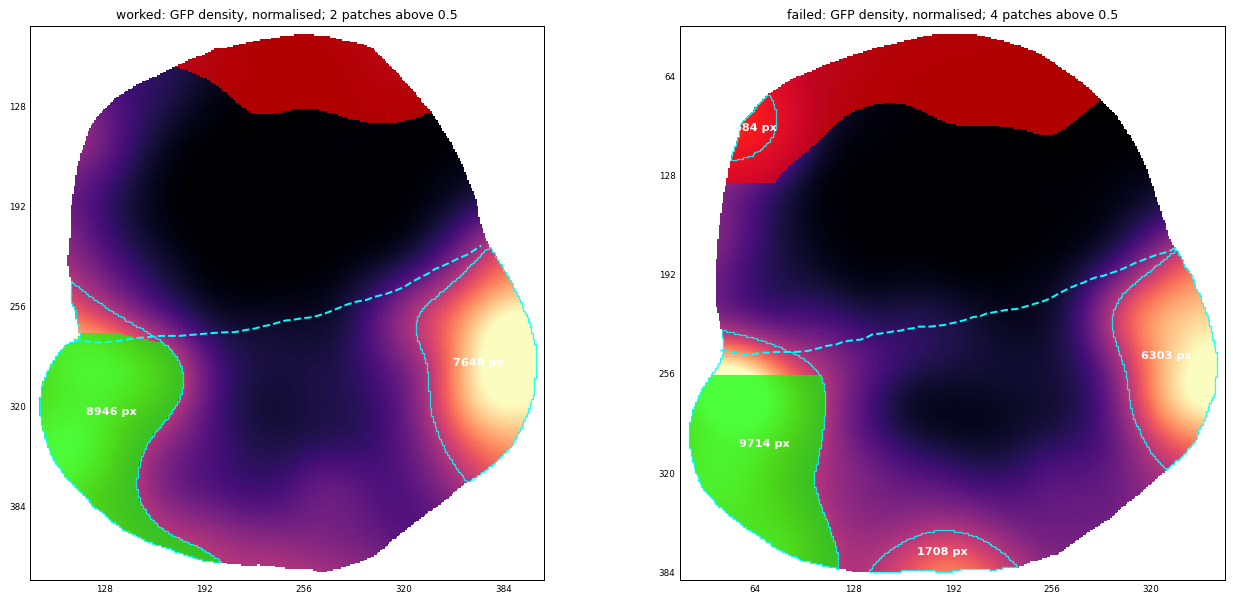

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
for ax, case, tag in zip(axes, (W, F), ("worked", "failed")):
    norm = jn._normalised(case.density, case.filled)
    patches, count = ndimage.label((norm > 0.5) & case.filled)
    sizes = np.bincount(patches.ravel())[1:]
    pixels(ax, np.where(case.filled, norm, np.nan), f"{tag}: GFP density, normalised; {count} patches above 0.5",
           cmap="magma", vmin=0, vmax=1)
    edges(ax, patches > 0, "cyan", 1)
    tint(ax, case.hot, "lime", 0.7); tint(ax, case.cold, "red", 0.7)
    for k, s in enumerate(sizes, start=1):
        rr, cc = np.argwhere(patches == k).mean(axis=0)
        ax.text(cc, rr, f"{s} px", color="white", ha="center", fontsize=9, weight="bold")
    hand(ax, case)
    limits(ax, case.view)
plt.tight_layout()

## Step 4 — the price of each pixel

`line_cost(stain, filled, um)`, on the block-averaged DAPI:

1. Off the tissue, every pixel is set to the **median of the tissue**, so the section's edge is not a dark line.
2. **fine** = Gaussian blur, σ = 8 µm (1.6 px): merges single nuclei, keeps the line.
3. **coarse** = Gaussian blur, σ = 60 µm (12 px): the level of the surroundings.
4. **ratio** = fine / coarse, clipped to 0.3 … 1. About 1 in the middle of either organoid, bright or dim, and below 1 on anything darker than its surroundings. Pixels *brighter* than their surroundings are clipped to 1, so a bright patch makes nothing more expensive.
5. **cost** = ratio⁶.

| ratio | 1.0 | 0.9 | 0.8 | 0.7 | 0.5 | 0.3 (floor) |
|---|---|---|---|---|---|---|
| cost | 1 | 0.53 | 0.26 | 0.12 | 0.016 | 0.0007 |

The profile runs down the same column as step 0. The deep trough on its left is a vertical crack, which this column runs along; the narrower dip at the hand-drawn line is the junction, and the power turns it into a valley.

Look at the price map: the hand-drawn junction (cyan) runs along a ribbon of cheap pixels, but it is **not the only one**. The dark vertical cracks across the upper organoid are just as cheap, and so is a thin rim along the section's edge.

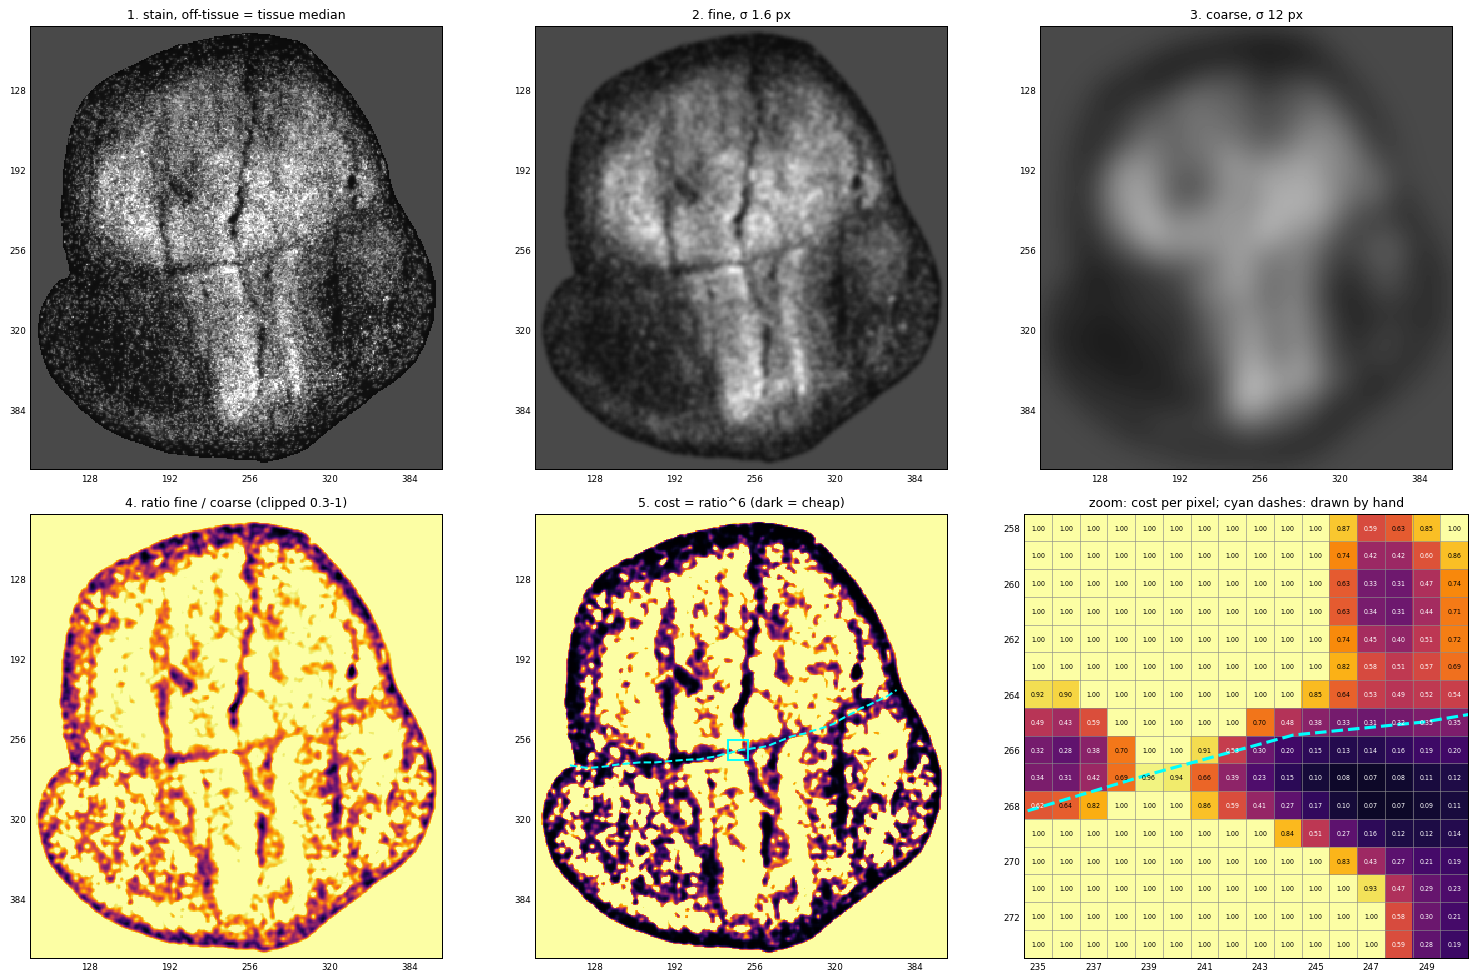

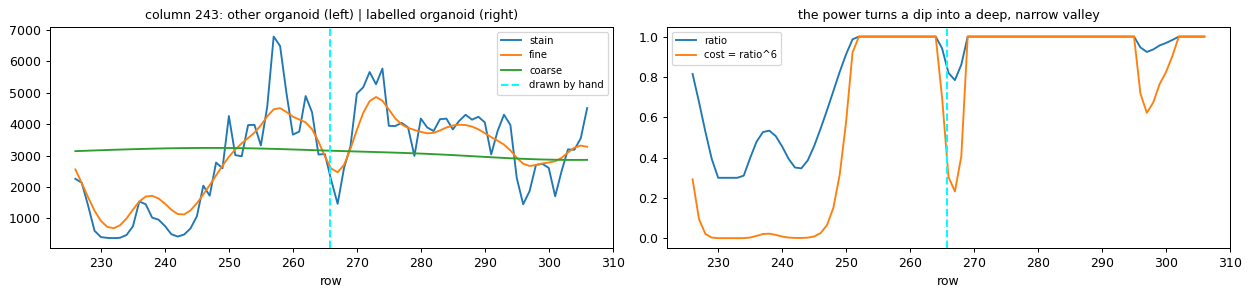

In [10]:
stain = overview.nuclear_mean
level = float(np.median(stain[filled]))
flat = np.where(filled, stain, level)
fine = ndimage.gaussian_filter(flat, jn.LINE_SMOOTH_UM / um)
coarse = ndimage.gaussian_filter(flat, jn.LINE_SURROUND_UM / um)
ratio = np.clip(fine / np.maximum(coarse, 1e-6), 0.3, 1.0)
cost = (ratio ** jn.LINE_POWER).astype(np.float32)
assert np.array_equal(cost, jn.line_cost(stain, filled, um))
assert np.array_equal(cost, W.cost)

fig, axes = plt.subplots(2, 3, figsize=(17, 11))
vmax = np.percentile(stain[filled], 99.5)
for ax, image, title in ((axes[0, 0], flat, "1. stain, off-tissue = tissue median"), (axes[0, 1], fine, "2. fine, σ 1.6 px"),
                         (axes[0, 2], coarse, "3. coarse, σ 12 px")):
    pixels(ax, image, title, vmin=0, vmax=vmax)
pixels(axes[1, 0], ratio, "4. ratio fine / coarse (clipped 0.3-1)", cmap="inferno", vmin=0.3, vmax=1)
pixels(axes[1, 1], cost, "5. cost = ratio^6 (dark = cheap)", cmap="inferno", vmin=0, vmax=1)
for ax in list(axes[0]) + list(axes[1, :2]):
    limits(ax, view)
hand(axes[1, 1], W)
z = (lr - 8, lc - 8, 16, 16)                                  # on the junction, where step 0 looked
pixels(axes[1, 2], crop(cost, *z), "zoom: cost per pixel; cyan dashes: drawn by hand", fmt=".2f", origin=z[:2],
       cmap="inferno", vmin=0, vmax=1, fontsize=5, every=2)
hand(axes[1, 2], W, lw=2.5)
limits(axes[1, 2], z)
window(axes[1, 1], *z)
plt.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
rows = np.arange(lr - 40, lr + 41)
cross = np.interp(lc, along[order, 1], along[order, 0])
for image, name in ((flat, "stain"), (fine, "fine"), (coarse, "coarse")):
    axes[0].plot(rows, image[rows, lc], "-", label=name)
axes[0].axvline(cross, **HAND, label="drawn by hand")
axes[0].legend(fontsize=8); axes[0].set_title(f"column {lc}: other organoid (left) | labelled organoid (right)"); axes[0].set_xlabel("row")
axes[1].plot(rows, ratio[rows, lc], "-", label="ratio")
axes[1].plot(rows, cost[rows, lc], "-", label="cost = ratio^6")
axes[1].axvline(cross, **HAND)
axes[1].legend(fontsize=8); axes[1].set_title("the power turns a dip into a deep, narrow valley"); axes[1].set_xlabel("row")
plt.tight_layout()

**Price under a line.** The price of a line is the mean cost of the pixels it runs over (1 = plain tissue). Below, both sections' price maps with the hand-drawn and the automatic line, then the price met **along** each line, from one end to the other (only the stretch on tissue). On the failed section the open tears (outlined in blue: the holes of step 1) sit at the price floor, and the finder's line runs down one of them.

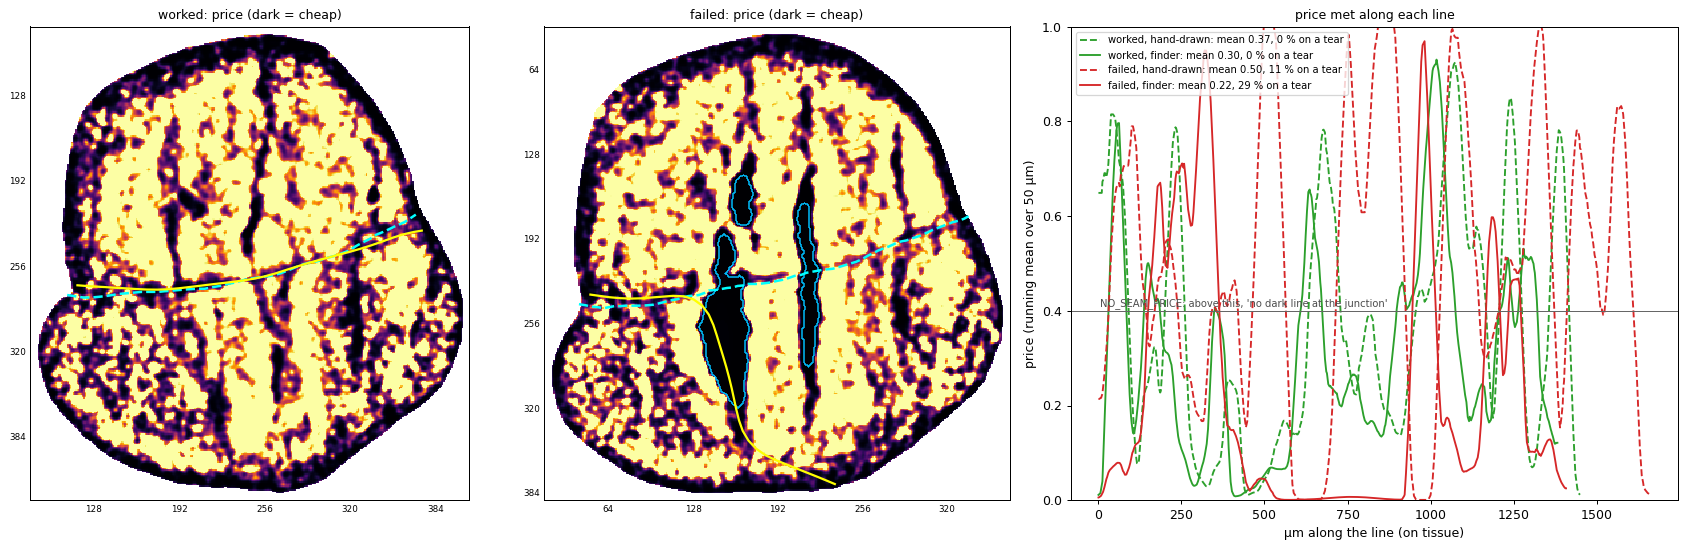

In [11]:
def price_along(case, line_um):
    """Cost of the pixels under *line_um*, every 2 µm along it, on the tissue only; and the position in µm."""
    points = jt.dense(line_um) / case.um
    rc = np.clip(np.round(points).astype(int), 0, np.array(case.filled.shape) - 1)
    on = case.filled[rc[:, 0], rc[:, 1]]
    return np.arange(on.sum()) * 2.0, case.cost[rc[on, 0], rc[on, 1]], (case.filled & ~case.tissue)[rc[on, 0], rc[on, 1]]


fig, axes = plt.subplots(1, 3, figsize=(19, 6.2), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, case, tag in zip(axes, (W, F), ("worked", "failed")):
    pixels(ax, np.where(case.filled, case.cost, np.nan), f"{tag}: price (dark = cheap)", cmap="inferno", vmin=0, vmax=1)
    edges(ax, case.filled & ~case.tissue, "deepskyblue", 1.2)
    hand(ax, case, lw=2)
    auto(ax, case.result.line_um, case.um)
    limits(ax, case.view)
for case, tag, colour in ((W, "worked", "tab:green"), (F, "failed", "tab:red")):
    for line, kind, style in ((case.manual_line, "hand-drawn", "--"), (case.result.line_um, "finder", "-")):
        position, price, torn = price_along(case, line)
        axes[2].plot(position, ndimage.uniform_filter1d(price, 25), style, color=colour,
                     label=f"{tag}, {kind}: mean {price.mean():.2f}, {100 * torn.mean():.0f} % on a tear")
axes[2].axhline(jn.NO_SEAM_PRICE, color="0.4", lw=0.8)
axes[2].text(5, jn.NO_SEAM_PRICE + 0.01, "NO_SEAM_PRICE: above this, 'no dark line at the junction'", fontsize=8, color="0.3")
axes[2].set_xlabel("µm along the line (on tissue)"); axes[2].set_ylabel("price (running mean over 50 µm)")
axes[2].set_ylim(0, 1); axes[2].legend(fontsize=8); axes[2].set_title("price met along each line")
plt.tight_layout()

## Step 5 — the minimum cut, on a graph you can count

`_min_cut(filled, hot, cold, cost)` turns pixels into a **graph**:

- every tissue pixel is a node;
- every pair of neighbouring tissue pixels is joined: to the right and below with **capacity** `mean(cost of the two) × 1000`, and diagonally with that × **0.7071**, rounded down to a whole number, at least 1. (Diagonal joins are weighted down because a straight boundary at 45° crosses them more densely; with the weight it costs the same per µm as one along the grid.)
- a **source** node joined to every pixel of the first seed, and a **sink** joined to every pixel of the second, both with a capacity of 2³⁰ (never cut).

SciPy's `maximum_flow` pushes as much as the joins can carry from source to sink. By the max-flow / min-cut theorem the flow is stopped by a set of saturated joins whose capacities add up to exactly that flow, and that set is the **cheapest set of joins whose removal separates the seeds**: the minimum cut. The pixels still reachable from the source through joins with capacity left over are side 1.

A real section has over a hundred thousand tissue pixels, too many to draw each join. So the operation is first shown on four **illustration** grids of 7 × 11 pixels with made-up prices (not a sample), the seeds in the left (green) and right (red) columns. Lines are joins, thicker when costlier; the joins cut are drawn in **cyan**, and their capacities summed in the title.

- **a** uniform cost: the cut is a straight line across, the shortest possible. Every column costs the same, so which one is found is arbitrary; here the first.
- **b** a slanted dark line (cost 0.1): longer than straight across, but cheaper, so the cut follows it.
- **c** one dark pixel only: saves the cost of one pixel's joins. The cut does pass through it, still straight.
- **d** the line of b with a gap of two pixels: the cut still follows it and crosses the gap; a dotted line is almost as good as a solid one.

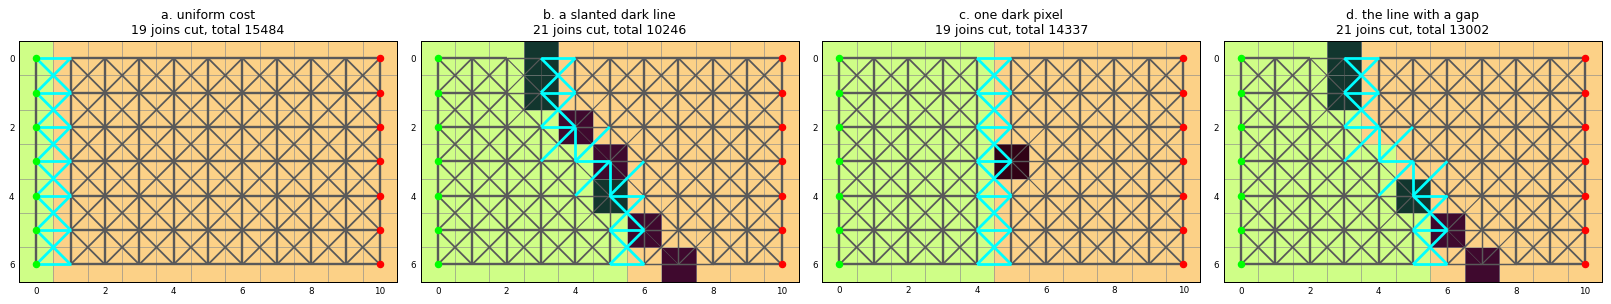

In [12]:
def demo_cut(ax, price, title):
    """Cut a small grid between its left and right column, and draw every join."""
    h, w = price.shape
    region = np.ones((h, w), bool)
    left = np.zeros((h, w), bool); left[:, 0] = True
    right = np.zeros((h, w), bool); right[:, -1] = True
    side = jn._min_cut(region, left, right, price.astype(np.float32))
    pixels(ax, price, "", cmap="inferno", vmin=0, vmax=1, every=2)
    tint(ax, side, "lime", 0.18); tint(ax, ~side, "red", 0.18)
    kept, cut_lines, kept_widths, cut_total = [], [], [], 0
    for dy, dx, weight in ((0, 1, 1.0), (1, 0, 1.0), (1, 1, 0.7071), (1, -1, 0.7071)):
        for r in range(h):
            for c in range(w):
                r2, c2 = r + dy, c + dx
                if 0 <= r2 < h and 0 <= c2 < w:
                    capacity = max(int((price[r, c] + price[r2, c2]) * 0.5 * weight * 1000), 1)
                    if side[r, c] != side[r2, c2]:
                        cut_lines.append([(c, r), (c2, r2)]); cut_total += capacity
                    else:
                        kept.append([(c, r), (c2, r2)]); kept_widths.append(0.3 + 1.6 * capacity / 1000)
    ax.add_collection(LineCollection(kept, colors="0.35", linewidths=kept_widths))
    ax.add_collection(LineCollection(cut_lines, colors="cyan", linewidths=2.2))
    ax.scatter(np.zeros(h), np.arange(h), c="lime", s=25, zorder=3)
    ax.scatter(np.full(h, w - 1), np.arange(h), c="red", s=25, zorder=3)
    ax.set_title(f"{title}\n{len(cut_lines)} joins cut, total {cut_total}")
    return side


h, w = 7, 11
uniform = np.ones((h, w))
slanted = uniform.copy()
for r in range(h):
    slanted[r, 3 + (4 * r) // (h - 1)] = 0.1
speck = uniform.copy(); speck[3, 5] = 0.05
gappy = slanted.copy(); gappy[3, 5] = gappy[2, 4] = 1.0

# Illustration grids, not a sample.
fig, axes = plt.subplots(1, 4, figsize=(18, 3.9))
for ax, price, title in zip(axes, (uniform, slanted, speck, gappy),
                            ("a. uniform cost", "b. a slanted dark line", "c. one dark pixel", "d. the line with a gap")):
    demo_cut(ax, price, title)
plt.tight_layout()

### The same on the worked section

Each side of the cut is then reduced to its **largest piece** (`split_tissue`), so a stray pixel cut off on the wrong side goes to nobody. Below: the halves, and the cut made with the DAPI price (yellow) and with a uniform price (magenta, *shape alone*), over the price map, with the hand-drawn line. By shape alone the cut is simply the shortest way round the smaller seed: across the top of the other organoid, far from the junction.

On this section the minimum cut alone does **not** follow the junction all the way: it runs along it from the left edge, then turns a corner and runs down a crack in the labelled organoid to the lower edge. A crack is a dark line too, and the cut only adds up what it crosses. Step 5b is what stops that.

tissue pixels 82686;  side 1 15260 px, of which the largest piece 15260
minimum cut, DAPI price   : line a mean 312 µm from the hand-drawn one (33 % within 100 µm)
minimum cut, shape alone  : line a mean 607 µm from the hand-drawn one (0 % within 100 µm)


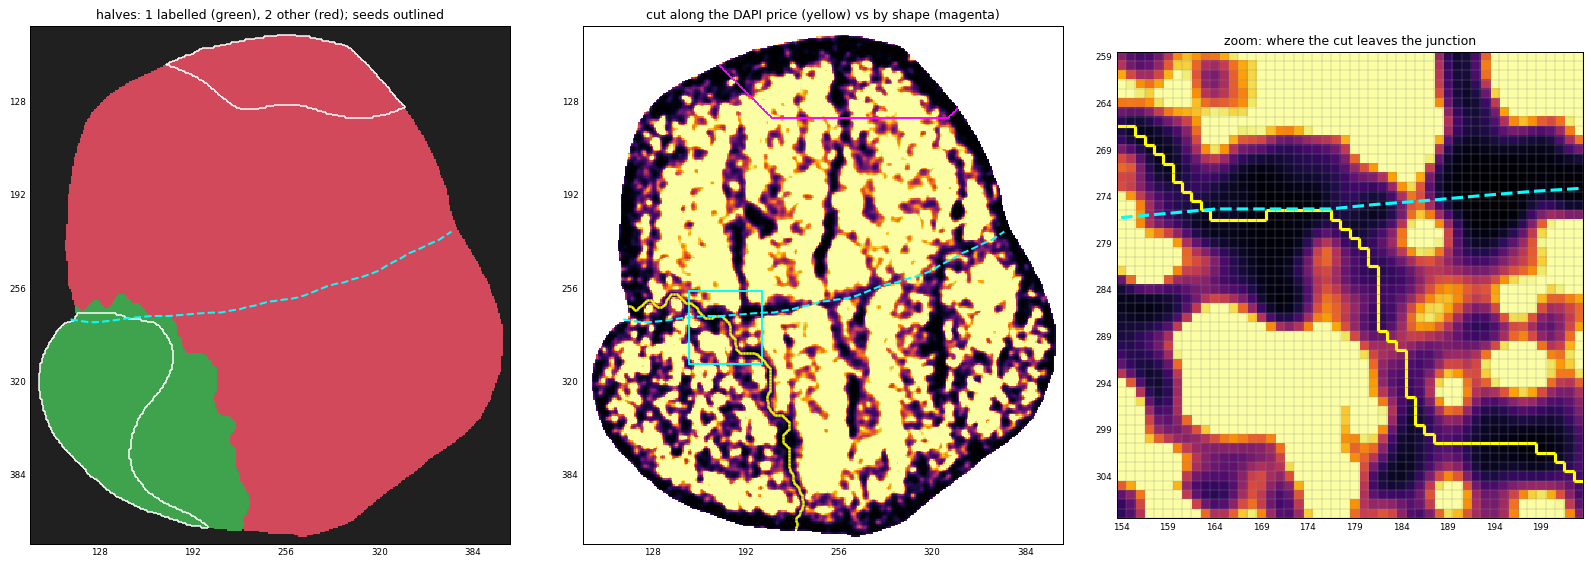

In [13]:
halves = jn.split_tissue(filled, density, um, cost, seeds=(hot_seed, cold))
by_shape = jn.split_tissue(filled, density, um, None, seeds=(hot_seed, cold))
side1 = jn._min_cut(filled, hot_seed, cold, cost)
assert np.array_equal(halves, W.halves_free)
print(f"tissue pixels {int(filled.sum())};  side 1 {int(side1.sum())} px, of which the largest piece {int((halves == 1).sum())}")
for name, sides in (("minimum cut, DAPI price", halves), ("minimum cut, shape alone", by_shape)):
    mean, hd95, within = off_by(W, line_of(sides, um))
    print(f"{name:26s}: line a mean {mean:.0f} µm from the hand-drawn one ({100 * within:.0f} % within 100 µm)")

fig, axes = plt.subplots(1, 3, figsize=(18, 6.2), gridspec_kw={"width_ratios": [1, 1, 0.9]})
pixels(axes[0], halves, "halves: 1 labelled (green), 2 other (red); seeds outlined", cmap=HALVES, vmin=0, vmax=2)
edges(axes[0], hot_seed, "white", 1.2); edges(axes[0], cold, "white", 1.2)
pixels(axes[1], np.where(filled, cost, np.nan), "cut along the DAPI price (yellow) vs by shape (magenta)", cmap="inferno", vmin=0, vmax=1)
edges(axes[1], halves == 1, "yellow", 2, against=halves == 2)
edges(axes[1], by_shape == 1, "magenta", 1.5, against=by_shape == 2)
for ax in axes[:2]:
    hand(ax, W)
    limits(ax, view)
from scipy.spatial import cKDTree
cut_px = np.argwhere(boundary(halves))
near = cKDTree(along).query(cut_px)[0] < 4                      # cut pixels on the hand-drawn line
corner = cut_px[near][np.argmax(cut_px[near][:, 1])]            # the last of them: where the cut turns away
z = (int(corner[0]) - 20, int(corner[1]) - 25, 50, 50)
pixels(axes[2], crop(np.where(filled, cost, np.nan), *z), "zoom: where the cut leaves the junction", cmap="inferno",
       vmin=0, vmax=1, origin=z[:2], every=5)
edges(axes[2], crop(halves == 1, *z), "yellow", 2.5, origin=z[:2], against=crop(halves == 2, *z))
hand(axes[2], W, lw=2.5)
limits(axes[2], z)
window(axes[1], *z)
plt.tight_layout()

## Step 5b — the cut again, paying for every turn

The minimum cut above only adds up what it crosses, so it turns any corner to follow something cheap: a crack, as on this section, or a tear. `straighten_cut` finds the cut a second time as a curve that pays for turning:

1. **Axis**: from the centre of the labelled seed to the centre of the other (white arrow). **Stations** are laid perpendicular to it every 20 µm (4.1 pixels), across the whole section; at each station the curve sits at one **offset** along the axis, in 5 µm steps, between the two seed centres.
2. **Price of a step** from one station to the next: the cut's own price (step 4) sampled at both ends and the middle, × the step's length in µm. Off the tissue it is 0; on a seed pixel it is prohibitive.
3. **Price of a turn**: `bend_um` × (change of heading ÷ 90°)². A heading is the step's angle; one station may move at most 6 offset steps (about 56°).
4. **Dynamic programming**: for every station, offset and heading, the cheapest way to get there, so the curve found is the cheapest over the whole section, not near the old cut.
5. The halves are the two sides of that curve. If both seeds end up on one side, the old halves are kept.

axis from (331, 133) to (111, 260); stations every 4.1 px, offsets every 1.03 px; a sharp 90° corner costs 1000 µm of plain tissue
cost of one turn, µm of plain tissue: {'0°': 0, '15°': 28, '30°': 111, '45°': 250, '60°': 444, '90°': 1000}


minimum cut alone : line a mean  312 µm from the hand-drawn one; price 0.30, sharpest turn 21°


bending costed    : line a mean   15 µm from the hand-drawn one; price 0.31, sharpest turn 4°


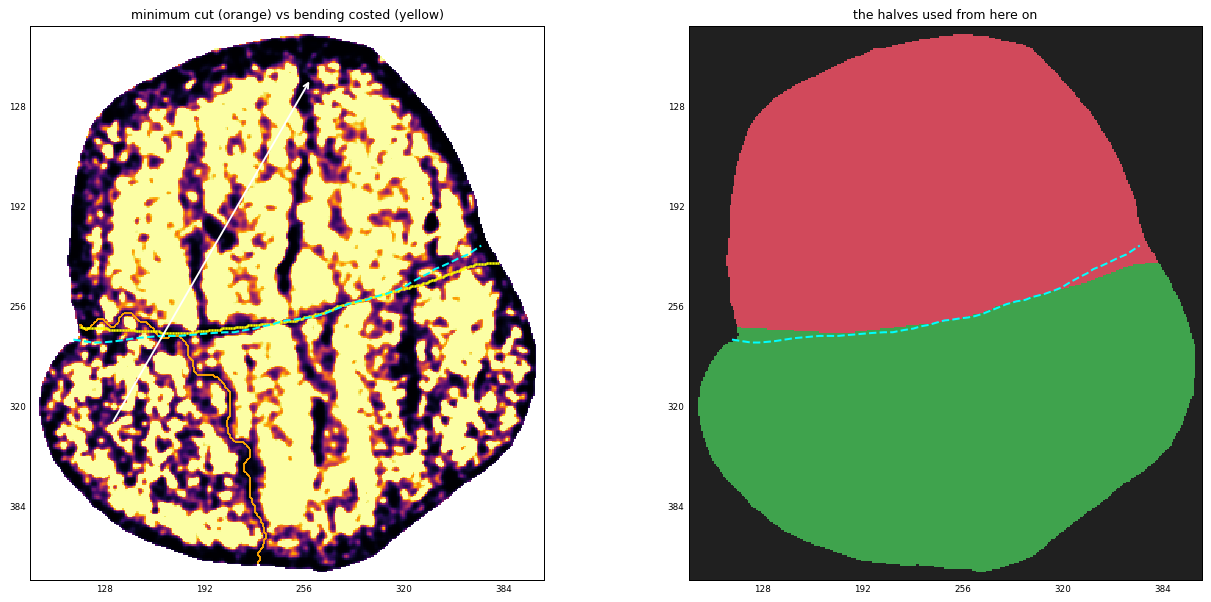

In [14]:
halves_free = halves                                         # step 5: the minimum cut alone
halves = jn.split_tissue(filled, density, um, cost, seeds=(hot_seed, cold), bend_um=options.bend_um)
assert np.array_equal(halves, W.halves)
hot_at, cold_at = np.argwhere(hot_seed & filled).mean(0), np.argwhere(cold & filled).mean(0)
print(f"axis from ({hot_at[0]:.0f}, {hot_at[1]:.0f}) to ({cold_at[0]:.0f}, {cold_at[1]:.0f}); "
      f"stations every {jn.BEND_STATION_UM / um:.1f} px, offsets every {jn.BEND_OFFSET_UM / um:.2f} px; "
      f"a sharp 90° corner costs {options.bend_um:.0f} µm of plain tissue")
turns = np.radians([0, 15, 30, 45, 60, 90])
print("cost of one turn, µm of plain tissue:", {f"{np.degrees(t):.0f}°": round(options.bend_um * (t / (np.pi / 2)) ** 2) for t in turns})
for name, sides in (("minimum cut alone", halves_free), ("bending costed", halves)):
    mean, hd95, within = off_by(W, line_of(sides, um))
    signs = jn.cut_signs(sides, cost, um)
    print(f"{name:18s}: line a mean {mean:4.0f} µm from the hand-drawn one; price {signs['Cut price']:.2f}, "
          f"sharpest turn {signs['Sharpest turn (deg)']:.0f}°")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
pixels(axes[0], np.where(filled, cost, np.nan), "minimum cut (orange) vs bending costed (yellow)", cmap="inferno", vmin=0, vmax=1)
edges(axes[0], halves_free == 1, "orange", 1.5, against=halves_free == 2)
edges(axes[0], halves == 1, "yellow", 2, against=halves == 2)
axes[0].annotate("", xy=cold_at[::-1], xytext=hot_at[::-1], arrowprops=dict(arrowstyle="->", color="white", lw=1.5))
pixels(axes[1], halves, "the halves used from here on", cmap=HALVES, vmin=0, vmax=2)
for ax in axes:
    hand(ax, W)
    limits(ax, view)
plt.tight_layout()

**On the failed section** the same two passes. The minimum cut (orange) leaves the junction near the left edge and runs down the long open tear to the lower edge, wrapping round the small lower-left seed. Here the bending pass (yellow) does **not** bring it back: it smooths the corner but still goes down the tear.

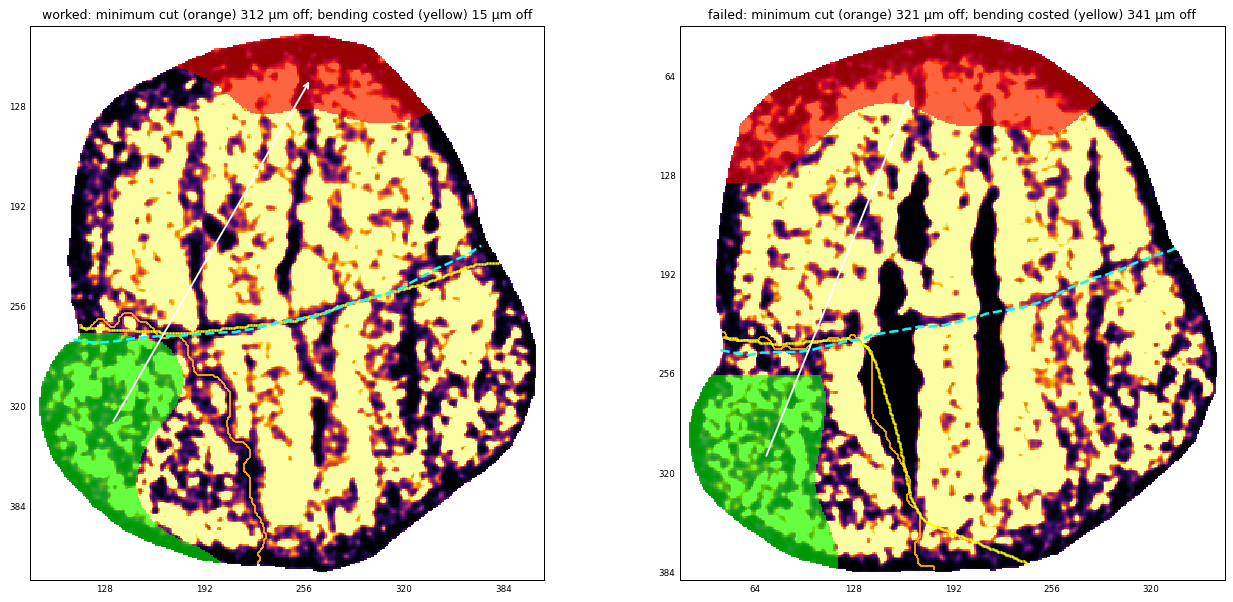

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
for ax, case, tag in zip(axes, (W, F), ("worked", "failed")):
    pixels(ax, np.where(case.filled, case.cost, np.nan), "", cmap="inferno", vmin=0, vmax=1)
    edges(ax, case.halves_free == 1, "orange", 1.5, against=case.halves_free == 2)
    edges(ax, case.halves == 1, "yellow", 2, against=case.halves == 2)
    tint(ax, case.hot, "lime", 0.6); tint(ax, case.cold, "red", 0.6)
    a, b = np.argwhere(case.hot).mean(0), np.argwhere(case.cold).mean(0)
    ax.annotate("", xy=b[::-1], xytext=a[::-1], arrowprops=dict(arrowstyle="->", color="white", lw=1.5))
    hand(ax, case, lw=2)
    limits(ax, case.view)
    free, bent = off_by(case, line_of(case.halves_free, case.um))[0], off_by(case, line_of(case.halves, case.um))[0]
    ax.set_title(f"{tag}: minimum cut (orange) {free:.0f} µm off; bending costed (yellow) {bent:.0f} µm off")
plt.tight_layout()

## Step 6 — from the cut to an ordered line

`trace_interface(halves, um)`:

1. **Touching pixels**: pixels of half 1 with a pixel of half 2 directly above, below, left or right of them.
2. **Thicken, then thin**: grow them by one pixel (so a chain broken only diagonally becomes one piece), keep the largest piece, and **skeletonise**: peel pixels off the outside, never breaking the shape, until a curve one pixel wide is left.
3. **Order** the curve. From any curve pixel, walk along the curve (8 directions, each step counting 1) to the pixel furthest away: that is one end. From there, the furthest pixel is the other end. The path between them, traced back step by step, is the curve in order (numbered below).
4. **Smooth** each coordinate along the path with a running mean of `round(150 µm / um)` = 31 points (at the ends the first and last point are repeated, which pulls the ends in a little), and keep every `round(40 µm / um)` = 8th point.

The zoom shows 24 × 24 pixels in the middle of the junction.

269 touching px -> skeleton of 269 px -> path of 269 -> 34 points


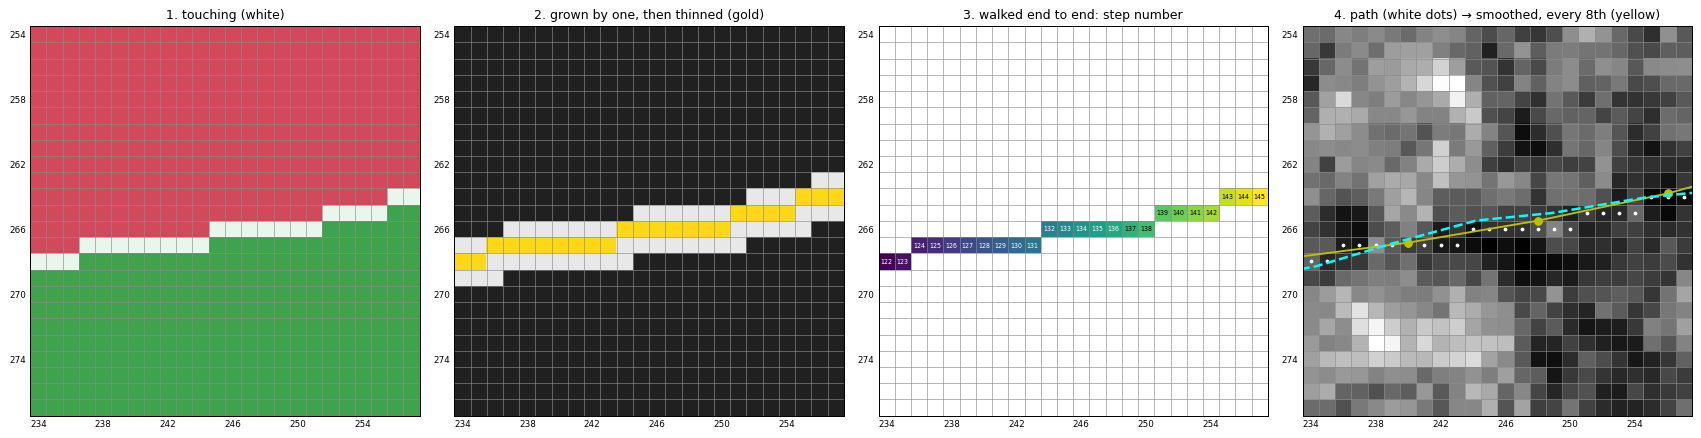

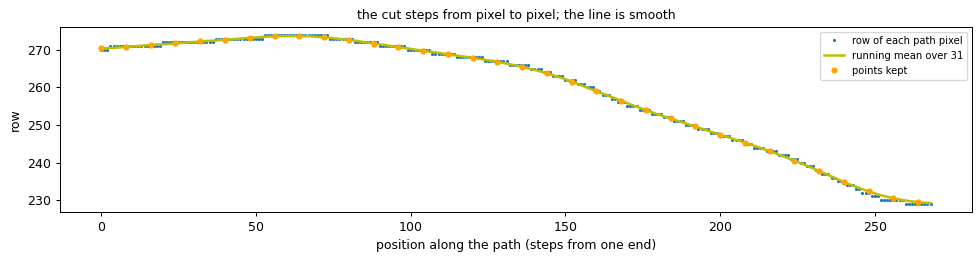

In [16]:
from skimage.graph import MCP
from skimage.morphology import skeletonize

touching = (halves == 1) & ndimage.binary_dilation(halves == 2)
thick = jn._largest(ndimage.binary_dilation(touching))
curve_mask = skeletonize(thick)
walk_cost = np.where(curve_mask, 1.0, 1e9)


def furthest(start):
    walk = MCP(walk_cost, fully_connected=True)
    costs, _ = walk.find_costs([tuple(start)])
    costs = np.where(curve_mask & (costs < 1e8), costs, -1.0)
    return tuple(int(n) for n in np.unravel_index(int(np.argmax(costs)), costs.shape)), walk, costs


one_end, _, steps_from_any = furthest(np.argwhere(curve_mask)[0])
other_end, walk, steps_from_end = furthest(one_end)
path = np.asarray(walk.traceback(other_end), dtype=float)
span = max(3, int(round(jn.JUNCTION_SMOOTH_UM / um)))
smooth_path = np.column_stack([ndimage.uniform_filter1d(path[:, k], span, mode="nearest") for k in (0, 1)])
line_px = smooth_path[:: max(1, int(round(40.0 / um)))]
assert np.allclose(line_px, jn.trace_interface(halves, um))
print(f"{int(touching.sum())} touching px -> skeleton of {int(curve_mask.sum())} px -> path of {len(path)} -> {len(line_px)} points")

centre = path[len(path) // 2].astype(int)
z = (int(centre[0]) - 12, int(centre[1]) - 12, 24, 24)
fig, axes = plt.subplots(1, 4, figsize=(19, 5.6))
pixels(axes[0], crop(halves, *z), "1. touching (white)", cmap=HALVES, vmin=0, vmax=2, origin=z[:2], every=4)
tint(axes[0], crop(touching, *z), "white", 0.9, origin=z[:2])
pixels(axes[1], crop(thick, *z), "2. grown by one, then thinned (gold)", cmap=MASK, origin=z[:2], every=4)
tint(axes[1], crop(curve_mask, *z), "gold", 0.9, origin=z[:2])
order_along = np.full(halves.shape, np.nan)
for index, (r, c) in enumerate(path.astype(int)):
    order_along[r, c] = index
pixels(axes[2], crop(order_along, *z), "3. walked end to end: step number", cmap="viridis", fmt=".0f", origin=z[:2], every=4, fontsize=5)
pixels(axes[3], crop(np.where(filled, stain, np.nan), *z), "4. path (white dots) → smoothed, every 8th (yellow)", origin=z[:2], every=4)
axes[3].plot(path[:, 1], path[:, 0], ".", color="white", ms=4)
axes[3].plot(line_px[:, 1], line_px[:, 0], "yo-", ms=6, lw=1.5)
hand(axes[3], W, lw=2)
limits(axes[3], z)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(path[:, 0], ".", color="tab:blue", ms=3, label="row of each path pixel")
ax.plot(smooth_path[:, 0], "y-", lw=2, label=f"running mean over {span}")
kept_idx = np.arange(0, len(path), max(1, int(round(40.0 / um))))
ax.plot(kept_idx, smooth_path[kept_idx, 0], "o", color="orange", ms=4, label="points kept")
ax.set_xlabel("position along the path (steps from one end)"); ax.set_ylabel("row"); ax.legend(fontsize=8)
ax.set_title("the cut steps from pixel to pixel; the line is smooth")
plt.tight_layout()

## Animation: from the seeds to the line

Steps 3 to 7 in motion, on the worked section:

1. **The price map** (step 4): dark where the nuclear stain dips, where cutting is cheap; and the two **seeds** (step 3): green on the labelled organoid, red on the other.
2. **An intuition for the cut, not the algorithm itself.** Water poured on each seed spreads through the tissue, quickly where the price is high (plain tissue: a wide pipe) and slowly where it is low (a dark line: a narrow one). Where the two floods meet is close to where the minimum cut goes: the cut is the set of narrow pipes that together carry the least, the bottleneck between the seeds. The maximum-flow solver (step 5) finds it exactly, all at once; the floods are only a way to see it.
3. **The minimum cut** (step 5): the boundary between the two sides, as the solver returns it, free to turn any corner (here: down a crack).
4. **The cut with a price on bending** (step 5b): the same, straightened; a 90° corner costs as much as cutting 1000 µm of plain tissue.
5. **The line** (step 6), drawn from one end to the other, and **the band** (step 7) on the side of the unlabelled organoid. The hand-drawn line appears with the band, dashed.

60 frames, 0.9 MB


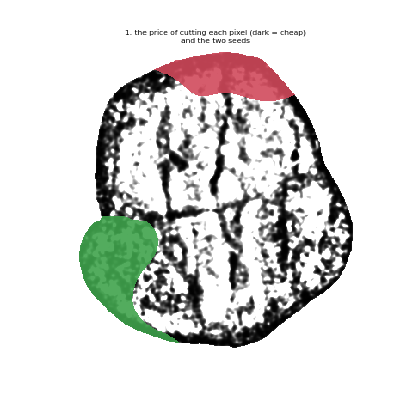

In [17]:
import tempfile

from IPython.display import Image
from matplotlib import animation
from skimage.graph import MCP_Geometric

anim_result = W.result

# Arrival time of water from each seed: time per pixel = 1 / price, so a dark line is slow to cross.
speed_cost = np.where(filled, 1.0 / np.maximum(cost, 0.05), np.inf)
arrival = []
for seed in (hot_seed & filled, cold & filled):
    mcp = MCP_Geometric(speed_cost)
    times, _ = mcp.find_costs(np.argwhere(seed))
    arrival.append(np.where(filled, times, np.inf))
first_wins = arrival[0] <= arrival[1]
meet_time = np.where(filled, np.minimum(*arrival), np.inf)
t_max = np.percentile(meet_time[np.isfinite(meet_time)], 99.5)

cut_free, cut_bent = boundary(halves_free), boundary(halves)
dense_line = fu.fit_spline(anim_result.line_um, spacing=um) / um
band_mask = anim_result.band
hand_px = manual_line_um / um

GREEN, RED = np.array([0.25, 0.64, 0.30]), np.array([0.82, 0.29, 0.36])
phases = [("price", 5), ("flood", 22), ("free", 7), ("bent", 7), ("line", 12), ("band", 7)]   # few frames: a light GIF
frames = [(name, k / max(1, n - 1)) for name, n in phases for k in range(n)]

fig, ax = plt.subplots(figsize=(7, 6.6))
ax.set_axis_off()
ax.imshow(np.where(filled, cost, np.nan), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
overlay = ax.imshow(np.zeros((*filled.shape, 4)), interpolation="nearest")
seed_rgba = np.zeros((*filled.shape, 4))
seed_rgba[hot_seed & filled] = (*GREEN, 0.9)
seed_rgba[cold & filled] = (*RED, 0.9)
seeds_im = ax.imshow(seed_rgba, interpolation="nearest")
(line_artist,) = ax.plot([], [], color="yellow", lw=3)
(hand_artist,) = ax.plot([], [], **HAND)
limits(ax, view)
title = ax.set_title("", fontsize=9)
CAPTIONS = {
    "price": "1. the price of cutting each pixel (dark = cheap)\nand the two seeds",
    "flood": "2. intuition: water from each seed,\nfast through plain tissue, slow across a dark line",
    "free": "3. the minimum cut: the cheapest boundary between the seeds\n(free to turn any corner: here down a crack)",
    "bent": "4. the cut again, with a price on every turn",
    "line": "5. the line, traced along the cut from one end to the other",
    "band": "6. the band, on the unlabelled organoid's side;\ncyan dashes: drawn by hand",
}


def colour(mask, rgb, alpha):
    out = np.zeros((*filled.shape, 4))
    out[mask] = (*rgb, alpha)
    return out


def draw(frame):
    name, f = frame
    title.set_text(CAPTIONS[name])
    rgba = np.zeros((*filled.shape, 4))
    if name == "flood":
        reached = meet_time <= f * t_max
        rgba = colour(reached & first_wins, GREEN, 0.45) + colour(reached & ~first_wins, RED, 0.45)
    elif name in ("free", "bent", "line", "band"):
        sides = halves_free if name == "free" else halves      # the solver's own two sides
        rgba = colour(sides == 1, GREEN, 0.18) + colour(sides == 2, RED, 0.18)
        rgba[cut_free] = (1.0, 0.55, 0.0, (f if name == "free" else 1.0) * (0.35 if name != "free" else 1.0))
        if name != "free":
            rgba[cut_bent] = (1.0, 0.85, 0.0, f if name == "bent" else 1.0)
        if name == "band":
            rgba[band_mask] = (0.2, 0.5, 1.0, 0.45 * f)
    overlay.set_data(np.clip(rgba, 0, 1))
    if name == "line":
        n = max(2, int(round(f * len(dense_line))))
        line_artist.set_data(dense_line[:n, 1], dense_line[:n, 0])
    elif name == "band":
        line_artist.set_data(dense_line[:, 1], dense_line[:, 0])
    else:
        line_artist.set_data([], [])
    hand_artist.set_data(*((hand_px[:, 1], hand_px[:, 0]) if name == "band" else ([], [])))
    return overlay, seeds_im, line_artist, hand_artist, title


movie = animation.FuncAnimation(fig, draw, frames=frames, blit=False)
with tempfile.TemporaryDirectory() as folder:
    target = Path(folder) / "junction.gif"
    movie.save(target, writer=animation.PillowWriter(fps=6), dpi=60)
    gif = target.read_bytes()
plt.close(fig)
print(f"{len(frames)} frames, {len(gif) / 1e6:.1f} MB")
Image(data=gif, format="gif")

The floods and the cut need not agree, and here they do not. The floods only say who arrives first, the cut what is cheapest to sever. On this section the floods meet on the junction in its left half, but on the right the red flood gets into the labelled organoid first; the minimum cut instead runs along the junction for a short stretch and then down a crack, which is almost free to cut. Neither is right everywhere; the bending price (step 5b) is what puts the line on the junction. That is the failure the evaluation notebook ([junction_evaluation.ipynb](../validation/junction_evaluation.ipynb)) found, and why the bending price of step 5b was added, and the random walker, which behaves much like the floods, was tried as an alternative.

## Step 7 — the band, pixel by pixel

`_build_band(result, overview, options)`. With the settings the hand-drawn band of this section was made with, the band is **300 µm** wide (62 px) and starts **2 µm** from the line (under half a pixel).

1. **Curve**: a cubic spline through the line's points, resampled every pixel (`fu.fit_spline`), and the **pixels it passes through**: each pair of consecutive points joined by a straight run of pixels (Bresenham's algorithm, `_draw_curve`).
2. **Distance**: for every pixel, the straight-line distance to the nearest line pixel (`distance_transform_edt`), × 4.875 µm.
3. **Side** (`_side_of_line`): the line is extended 40 px past both ends along its end direction (the smoothed line stops short of the outline), drawn, and grown by one pixel into a **wall**. The wall splits the tissue into pieces; each piece goes to the side most of its pixels were on in the cut. The side is then grown back by one pixel, so the wall itself is not lost.
3b. **Rim past the edge** (`margin_um`, 10 µm = 2 px here): every pixel *off* the tissue within that distance of the chosen side joins the side and the tissue, so cells migrating over the organoid's surface, just outside the outline, are in the band. Pixels of the other organoid's tissue are never added: they are not off the tissue.
4. **Rounded tissue** (`_smooth_mask`): blur the mask with σ = 25 µm (5.1 px) and keep pixels above 0.5. Corners and slivers narrower than σ go; straight edges stay where they were. A small **illustration** comes first (a made-up mask, not the sample).
5. **Band** = side ∧ rounded tissue ∧ 2 µm ≤ distance ≤ 302 µm, then rounded the same way, cut again to distance ≥ 2 µm and to the rounded tissue, and its largest piece kept.

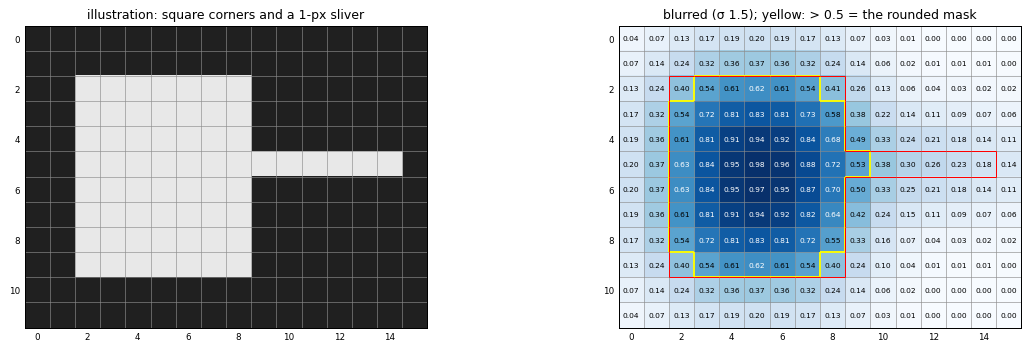

In [18]:
# An illustration of the rounding, not the sample.
toy = np.zeros((12, 16), bool)
toy[2:10, 2:9] = True                    # a block with right-angled corners
toy[5, 9:15] = True                      # a one-pixel sliver
toy_blur = ndimage.gaussian_filter(toy.astype(np.float32), 1.5)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pixels(axes[0], toy, "illustration: square corners and a 1-px sliver", cmap=MASK, every=2)
pixels(axes[1], toy_blur, "blurred (σ 1.5); yellow: > 0.5 = the rounded mask", fmt=".2f", cmap="Blues", every=2, fontsize=6)
edges(axes[1], jn._smooth_mask(toy, 1.5))
edges(axes[1], toy, "red", 0.8)
plt.tight_layout()

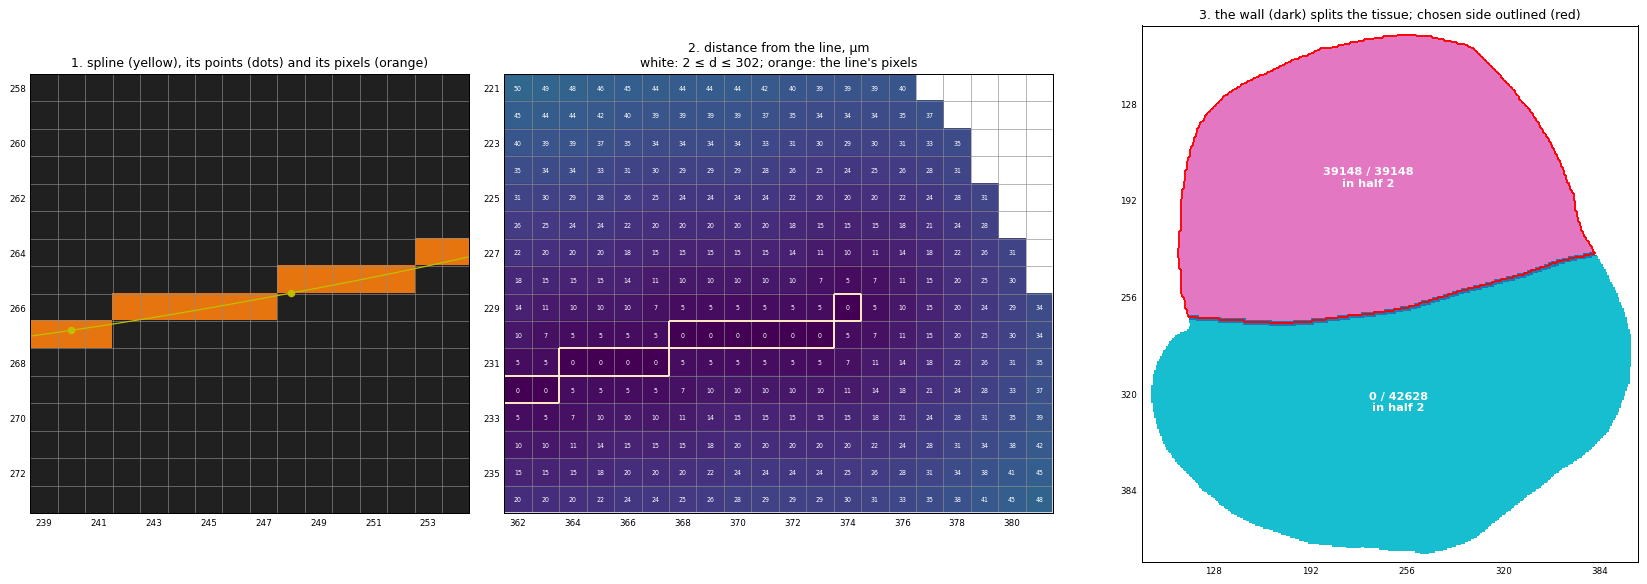

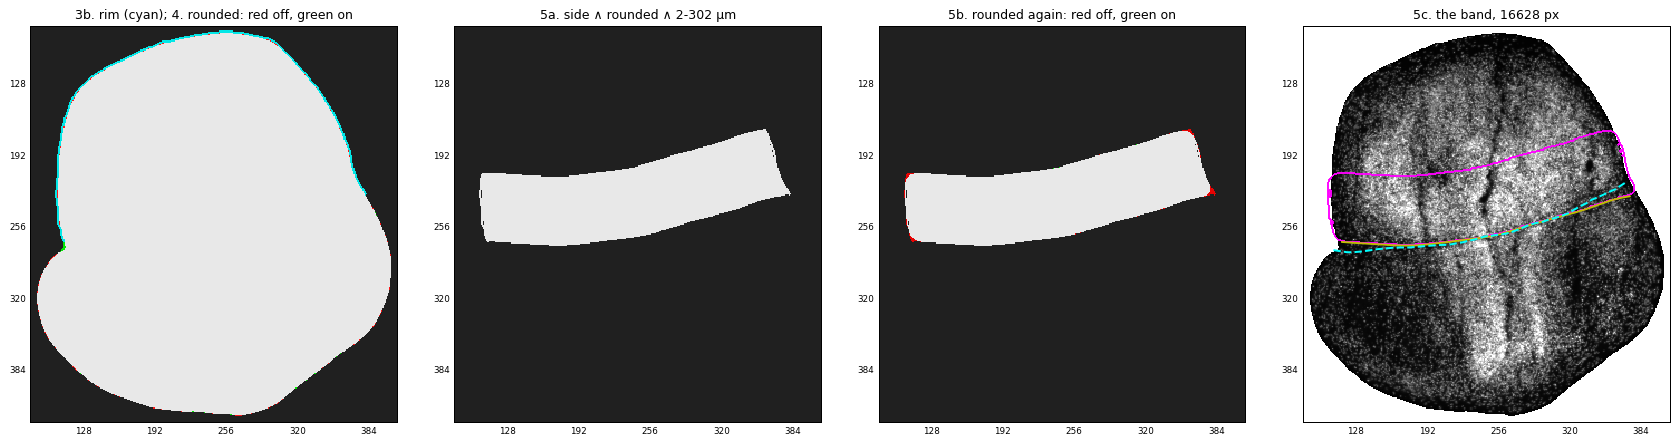

In [19]:
result = W.result                                    # steps 1-7 in one call: find_junction
assert np.array_equal(result.halves, halves)
gap, width = float(options.gap_um), float(options.width_um)
spline = fu.fit_spline(result.line_um, spacing=um)
on_line = jn._draw_curve(spline / um, filled.shape)
distance = ndimage.distance_transform_edt(~on_line) * um

# _side_of_line, step by step.
c = spline / um
head = c[0] + (c[0] - c[3]) / np.linalg.norm(c[0] - c[3]) * 40.0
tail = c[-1] + (c[-1] - c[-4]) / np.linalg.norm(c[-1] - c[-4]) * 40.0
wall = ndimage.binary_dilation(jn._draw_curve(np.vstack((head, c, tail)), filled.shape), np.ones((3, 3), bool))
wanted = result.halves == (2 if options.into_unlabelled else 1)
parts, n_parts = ndimage.label(filled & ~wall)
votes = ndimage.sum(wanted, parts, index=np.arange(1, n_parts + 1))
part_sizes = ndimage.sum(np.ones_like(wanted), parts, index=np.arange(1, n_parts + 1))
chosen = np.isin(parts, np.flatnonzero(votes > 0.5 * part_sizes) + 1)
target = ndimage.binary_dilation(chosen, np.ones((3, 3), bool)) & filled
assert np.array_equal(target, jn._side_of_line(result, c, options.into_unlabelled))

rounded = jn._smooth_mask(filled, jn.SMOOTH_UM / um)
rim = (ndimage.distance_transform_edt(~target) * um <= options.margin_um) & ~filled   # 3b. past the edge
target, rounded = target | rim, rounded | rim
first_cut = target & rounded & (distance <= gap + width) & (distance >= gap)
second = jn._smooth_mask(first_cut, jn.SMOOTH_UM / um) & rounded & (distance >= gap)
band = jn._largest(second)
assert np.array_equal(band, result.band)

fig, axes = plt.subplots(1, 3, figsize=(19, 6.6), gridspec_kw={"width_ratios": [0.8, 1, 1.1]})
mid = np.round(spline[len(spline) // 2] / um).astype(int)
z = (int(mid[0]) - 8, int(mid[1]) - 8, 16, 16)
pixels(axes[0], crop(filled, *z), "1. spline (yellow), its points (dots) and its pixels (orange)", cmap=MASK, origin=z[:2], every=2)
tint(axes[0], crop(on_line, *z), "tab:orange", 0.9, origin=z[:2])
axes[0].plot(spline[:, 1] / um, spline[:, 0] / um, "y-", lw=1)
axes[0].plot(result.line_um[:, 1] / um, result.line_um[:, 0] / um, "yo", ms=5)
limits(axes[0], z)
end = np.round(spline[-1] / um).astype(int)                # round one end of the line
z2 = (int(end[0]) - 8, int(end[1]) - 12, 16, 20)
pixels(axes[1], crop(np.where(filled, distance, np.nan), *z2), "2. distance from the line, µm", fmt=".0f", cmap="viridis",
       origin=z2[:2], vmax=150, every=2, fontsize=5)
edges(axes[1], crop(on_line, *z2), "orange", 1.5, origin=z2[:2])
edges(axes[1], crop((distance >= gap) & (distance <= gap + width), *z2), "white", 1.2, origin=z2[:2])
axes[1].set_title(axes[1].get_title() + f"\nwhite: {gap:.0f} ≤ d ≤ {gap + width:.0f}; orange: the line's pixels")
show_parts = np.where(wall & filled, -1, parts).astype(float)
show_parts[~filled] = np.nan
pixels(axes[2], show_parts, "3. the wall (dark) splits the tissue; chosen side outlined (red)", cmap="tab10")
for index in range(1, n_parts + 1):
    if part_sizes[index - 1] < 200:
        continue
    rr, cc = np.argwhere(parts == index).mean(axis=0)
    axes[2].text(cc, rr, f"{int(votes[index - 1])} / {int(part_sizes[index - 1])}\nin half 2", ha="center", fontsize=9,
                 color="white", weight="bold")
edges(axes[2], target & filled, "red", 1.5)
limits(axes[2], view)
plt.tight_layout()

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))
pixels(axes[0], filled, "3b. rim (cyan); 4. rounded: red off, green on", cmap=MASK)
tint(axes[0], filled & ~rounded, "red", 0.9); tint(axes[0], rounded & ~filled & ~rim, "lime", 0.9)
tint(axes[0], rim, "cyan", 0.9)
pixels(axes[1], first_cut, f"5a. side ∧ rounded ∧ {gap:.0f}-{gap + width:.0f} µm", cmap=MASK)
pixels(axes[2], second, "5b. rounded again: red off, green on", cmap=MASK)
tint(axes[2], first_cut & ~second, "red", 0.9); tint(axes[2], second & ~first_cut, "lime", 0.9)
pixels(axes[3], np.where(filled, stain, np.nan), f"5c. the band, {int(band.sum())} px", vmax=vmax)
edges(axes[3], band, "magenta", 1.5)
axes[3].plot(spline[:, 1] / um, spline[:, 0] / um, "y-", lw=1.5)
hand(axes[3], W)
for ax in axes:
    limits(ax, view)
plt.tight_layout()

## Step 8 — onto the full-resolution grid

Cells are measured at 0.325 µm per pixel, so the band (about 500 × 500 overview pixels) has to go onto the 7 584 × 7 567 grid of the scan.

1. **Outline** (`_outline`): `find_contours` at level 0.5 on the band mask (padded by one pixel so a band touching the border is still closed). The contour runs through the midpoints of pixel edges, so it cuts every corner of the staircase diagonally. It is then smoothed with a running mean of 5 points, wrapping round since the outline is closed.
2. **Mapping**: overview pixel *k* stands for full-resolution pixels *15k … 15k + 14*, centred on *15k + 7*. So an outline point at overview position *p* (in µm: *p × 4.875*) lands at full-resolution position `p × 4.875 µm / 0.325 µm + (15 − 1) / 2`.
3. **Fill** (`fu.fill_polygon`): Pillow's scanline fill of that polygon, within its bounding box.

Compared below with simply blowing the overview mask up 15 times (each pixel a 15 × 15 block): that is a staircase of 15-pixel (4.9 µm) steps. The window is read **from the scan itself**, on the far edge of the band, 300 µm from the line.

outline: 761 points; full-resolution band 3746077 px (0.3957 mm²)
in the window: staircase 5175 px, outline fill 5234 px, they differ on 263 px


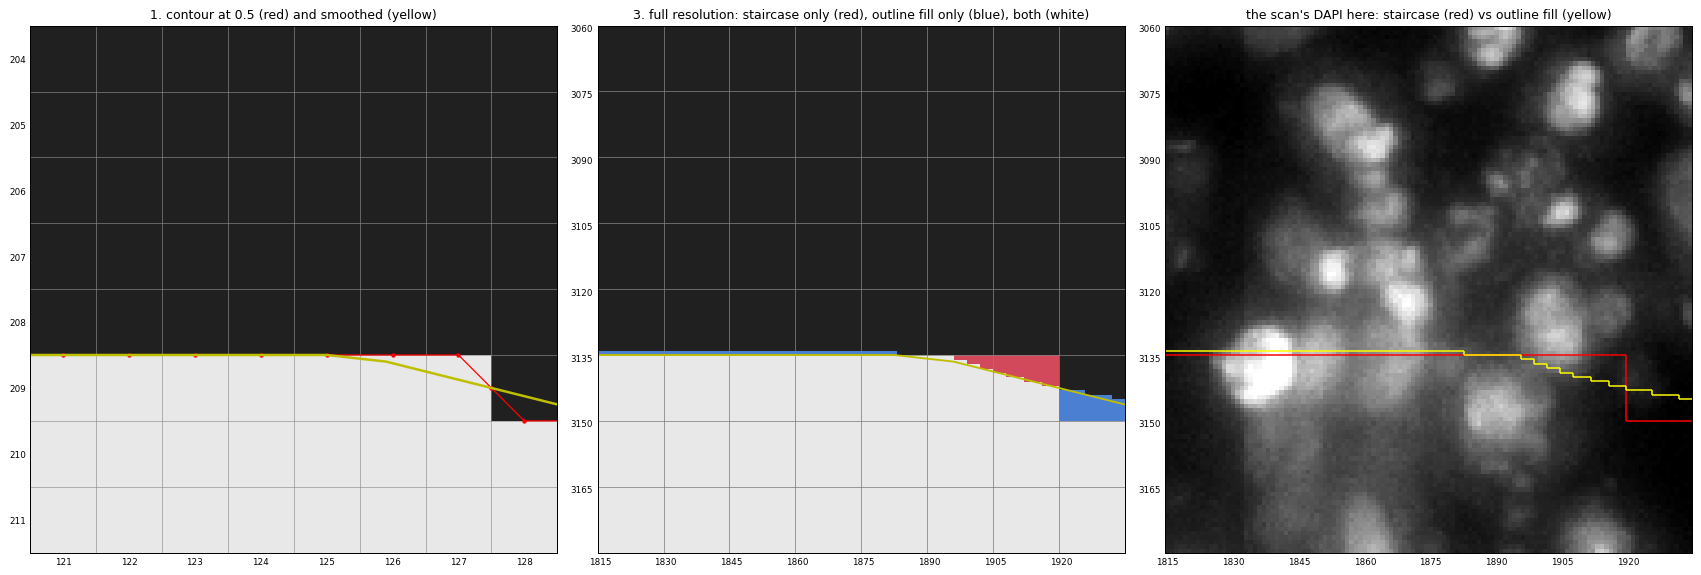

In [20]:
from skimage.measure import find_contours

contours = find_contours(np.pad(band, 1).astype(float), 0.5)
raw_outline = max(contours, key=len) - 1.0
smoothed_outline = np.column_stack([ndimage.uniform_filter1d(raw_outline[:, k], 5, mode="wrap") for k in (0, 1)])
assert np.allclose(smoothed_outline[:: max(1, len(smoothed_outline) // 600)] * um, result.band_outline_um)
labels_full = jn.full_resolution_band(result, overview, options)
print(f"outline: {len(raw_outline)} points; full-resolution band {int(labels_full.sum())} px "
      f"({labels_full.sum() * np.prod(overview.voxel_yx) / 1e6:.4f} mm²)")

# The far edge of the band: the outline point furthest from the line, away from the section's edge.
inside = ndimage.binary_erosion(filled, iterations=12)
candidates = [p for p in smoothed_outline if inside[int(round(p[0])), int(round(p[1]))]]
far = max(candidates, key=lambda p: distance[int(round(p[0])), int(round(p[1]))])
z = (int(far[0]) - 4, int(far[1]) - 4, 8, 8)                     # 8 x 8 overview pixels
f = (z[0] * step, z[1] * step, z[2] * step, z[3] * step)         # = 120 x 120 pixels of the scan
staircase = np.kron(crop(band, *z), np.ones((step, step), bool))
filled_full = crop(labels_full, *f) > 0
specs = loaders.load_path(RAW)
dapi_full = read_window(nuclear, *f).max(axis=0)
loaders.release(RAW)
print(f"in the window: staircase {int(staircase.sum())} px, outline fill {int(filled_full.sum())} px, "
      f"they differ on {int((staircase ^ filled_full).sum())} px")

fig, axes = plt.subplots(1, 3, figsize=(19, 6.4))
pixels(axes[0], crop(band, *z), "1. contour at 0.5 (red) and smoothed (yellow)", cmap=MASK, origin=z[:2], every=1)
axes[0].plot(raw_outline[:, 1], raw_outline[:, 0], "r.-", lw=1, ms=5)
axes[0].plot(smoothed_outline[:, 1], smoothed_outline[:, 0], "y-", lw=2)
limits(axes[0], z)
both = staircase.astype(int) + 2 * filled_full
pixels(axes[1], both, "3. full resolution: staircase only (red), outline fill only (blue), both (white)",
       cmap=ListedColormap(["#202020", "#d1495b", "#4a7fd1", "#e8e8e8"]), vmin=0, vmax=3, origin=f[:2], every=step)
for k in range(0, f[3] + 1, step):
    axes[1].axvline(f[1] + k - 0.5, color="0.5", lw=0.6)
for k in range(0, f[2] + 1, step):
    axes[1].axhline(f[0] + k - 0.5, color="0.5", lw=0.6)
mapped = smoothed_outline * um / overview.voxel_yx[0] + (step - 1) / 2.0
axes[1].plot(mapped[:, 1], mapped[:, 0], "y-", lw=1.5)
limits(axes[1], f)
pixels(axes[2], dapi_full, "the scan's DAPI here: staircase (red) vs outline fill (yellow)", origin=f[:2], every=step,
       vmin=np.percentile(dapi_full, 1), vmax=np.percentile(dapi_full, 99.5))
edges(axes[2], staircase, "red", 1.2, origin=f[:2], against=~staircase)          # not along the window's border
edges(axes[2], filled_full, "yellow", 1.2, origin=f[:2], against=~filled_full)
plt.tight_layout()

## Step 9 — the quality figures, pixel by pixel

Each figure `quality_flags` reads is a count of pixels or a mean over them:

| Figure | Pixels counted | Flag when |
|---|---|---|
| Hole share | (filled − tissue) / filled | > 10 % |
| Solidity | largest piece of filled / its **convex hull** (the smallest convex shape holding it) | < 0.75 |
| Cut off by the scan | outline pixels of `filled` that lie within 2 px of where `valid` stops, / all outline pixels | > 5 % |
| Second piece share | second-largest piece of tissue / largest | ≥ 25 % (fail) |
| Seam price | mean price (step 4) of the pixels under the junction line | > 0.4 (`NO_SEAM_PRICE`): *no dark line at the junction* |
| Labelled share | half 1 / filled | < 10 % or > 90 % |
| Density contrast | mean GFP density over half 1 / over half 2 | < 1.8 |

`tissue_metrics` also records the section's **shape** (perimeter, long and short axis, four shape numbers that do not change with size or rotation), and `result.signature` is a small fixed-scale picture of the outline and its labelled half. Those are for matching serial sections of one assembloid; no flag reads them.

The folder-wide checks (`flag_cohort`) take a figure over all samples, its log, and flag a sample whose robust z — (log − median) / (MAD × 1.4826) — is beyond 3.5.

Below, the pixels behind each figure on both sections (top: worked, bottom: failed), then their figures side by side.

                                 worked     failed
  Tissue area (mm2)                1.97       2.09
  Pieces                              1          1
  Hole share                          0     0.0468
  Solidity                        0.983      0.986
  Cut off by the scan                 0          0
  Seam price                      0.308      0.234
  Sharpest turn (deg)              4.43       18.3
  Labelled share of tissue        0.522        0.2
  Density contrast                 2.08        1.9
  Junction length (um)         1.29e+03   1.31e+03
  Band tissue area (mm2)          0.391      0.415
worked: status OK, flags: none
failed: status OK, flags: none
shape numbers of the worked section: {'Shape 1': 0.79, 'Shape 2': 3.39, 'Shape 3': 3.94, 'Shape 4': 6.4} ; signature (2, 64, 64)

illustration, cohort check: tissue areas [1.9 2.1 2.  1.8 2.3 2.2 1.7 2.  2.1 0.4] 
 robust z [ -0.5   0.4   0.   -1.    1.3   0.9  -1.5   0.    0.4 -14.8] 
 flagged: [0.4]


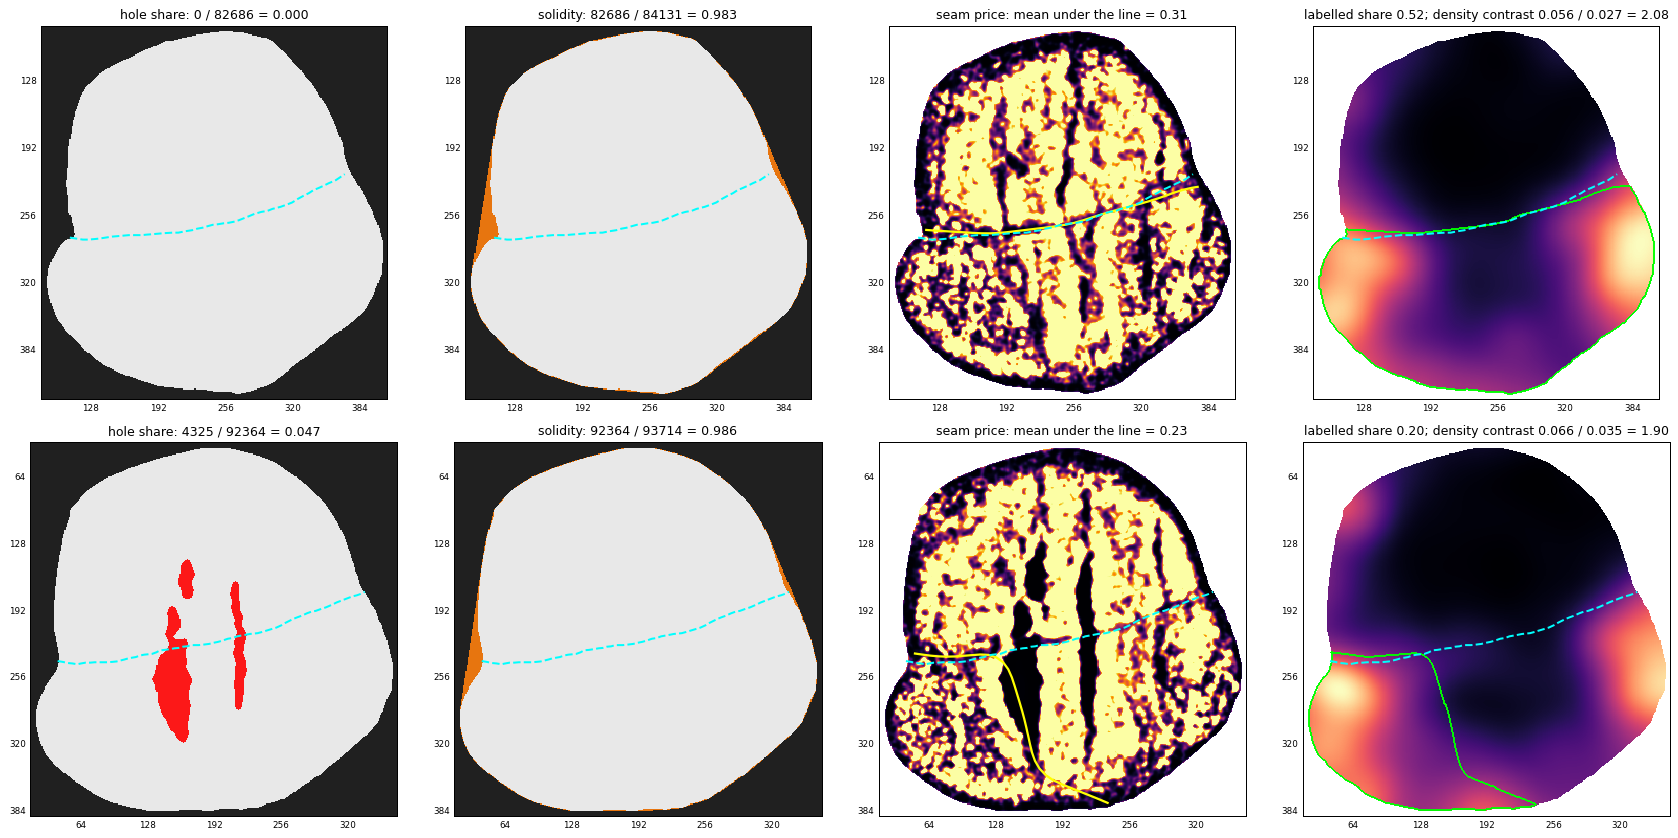

In [21]:
from skimage.morphology import convex_hull_image

fig, axes = plt.subplots(2, 4, figsize=(19, 9.4))
for row, case in zip(axes, (W, F)):
    f_, t_ = case.filled, case.tissue
    hull = convex_hull_image(jn._largest(f_))
    border = ~ndimage.binary_erosion(case.valid, iterations=2, border_value=0)
    outline_px = f_ & ~ndimage.binary_erosion(f_)
    m = case.result.metrics
    pixels(row[0], f_, f"hole share: {int((f_ & ~t_).sum())} / {int(f_.sum())} = {m['Hole share']:.3f}", cmap=MASK)
    tint(row[0], f_ & ~t_, "red", 0.9)
    pixels(row[1], f_, f"solidity: {int(f_.sum())} / {int(hull.sum())} = {m['Solidity']:.3f}", cmap=MASK)
    tint(row[1], hull & ~f_, "tab:orange", 0.9)
    pixels(row[2], np.where(f_, case.cost, np.nan), f"seam price: mean under the line = {m['Seam price']:.2f}",
           cmap="inferno", vmin=0, vmax=1)
    auto(row[2], case.result.line_um, case.um)
    pixels(row[3], np.where(f_, case.density, np.nan), "", cmap="magma")
    edges(row[3], case.halves == 1, "lime", 1.5)
    row[3].set_title(f"labelled share {m['Labelled share of tissue']:.2f}; density contrast "
                     f"{case.density[case.halves == 1].mean():.3f} / {case.density[case.halves == 2].mean():.3f} = {m['Density contrast']:.2f}")
    for ax in row:
        hand(ax, case)
        limits(ax, case.view)
plt.tight_layout()

keys = ("Tissue area (mm2)", "Pieces", "Hole share", "Solidity", "Cut off by the scan", "Seam price",
        "Sharpest turn (deg)", "Labelled share of tissue", "Density contrast", "Junction length (um)", "Band tissue area (mm2)")
print(f"{'':28s} {'worked':>10s} {'failed':>10s}")
for key in keys:
    print(f"  {key:26s} {W.result.metrics[key]:10.3g} {F.result.metrics[key]:10.3g}")
for case, tag in ((W, "worked"), (F, "failed")):
    print(f"{tag}: status {case.result.status.upper()}, flags: {'; '.join(case.result.flags) or 'none'}")
print("shape numbers of the worked section:", {k: round(v, 2) for k, v in W.result.metrics.items() if k.startswith("Shape")},
      "; signature", W.result.signature.shape)

# The cohort check, as an illustration on ten made-up tissue areas (not samples): one is far too small.
areas = np.array([1.9, 2.1, 2.0, 1.8, 2.3, 2.2, 1.7, 2.0, 2.1, 0.4])
logs = np.log(areas)
robust_z = (logs - np.median(logs)) / (np.median(np.abs(logs - np.median(logs))) * 1.4826)
print("\nillustration, cohort check: tissue areas", areas, "\n robust z", np.round(robust_z, 1),
      "\n flagged:", areas[np.abs(robust_z) > jn.COHORT_Z])

## Where the failed section goes wrong

The steps above, put together on the failed section. Three figures, then the explanation.

**1. Where the seeds land and where the cut goes.** Left: the GFP density; the labelled seed (green) covers only the lower-left patch of the labelled organoid, the other seed (red) the top of the other organoid. Middle: the price map, with the holes left by the tears (blue), the hand-drawn line and the finder's line. Right: the two halves the finder made.

failed, hand-drawn line:  1662 µm on tissue, mean price 0.50, price x length  827 µm, 11 % of it on a tear
failed, finder's line  :  1408 µm on tissue, mean price 0.22, price x length  313 µm, 29 % of it on a tear


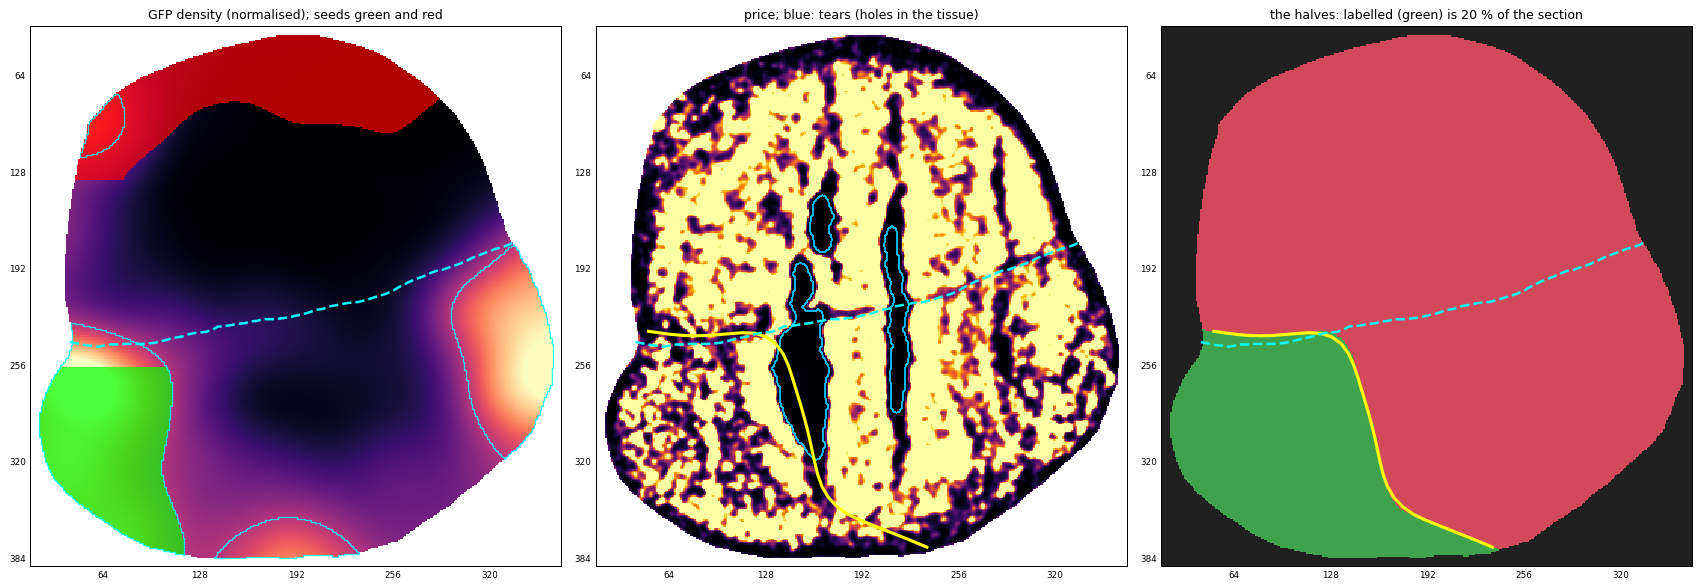

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6.6))
norm = jn._normalised(F.density, F.filled)
pixels(axes[0], np.where(F.filled, norm, np.nan), "GFP density (normalised); seeds green and red", cmap="magma", vmin=0, vmax=1)
edges(axes[0], (norm > 0.5) & F.filled, "cyan", 1)
tint(axes[0], F.hot, "lime", 0.7); tint(axes[0], F.cold, "red", 0.7)
pixels(axes[1], np.where(F.filled, F.cost, np.nan), "price; blue: tears (holes in the tissue)", cmap="inferno", vmin=0, vmax=1)
edges(axes[1], F.filled & ~F.tissue, "deepskyblue", 1.5)
auto(axes[1], F.result.line_um, F.um, lw=2.5)
pixels(axes[2], F.halves, f"the halves: labelled (green) is {100 * F.result.metrics['Labelled share of tissue']:.0f} % of the section",
       cmap=HALVES, vmin=0, vmax=2)
auto(axes[2], F.result.line_um, F.um, lw=2.5)
for ax in axes:
    hand(ax, F, lw=2)
    limits(ax, F.view)
plt.tight_layout()

for name, line in (("hand-drawn line", F.manual_line), ("finder's line", F.result.line_um)):
    position, price, torn = price_along(F, line)
    print(f"failed, {name:15s}: {position[-1]:5.0f} µm on tissue, mean price {price.mean():.2f}, "
          f"price x length {price.sum() * 2:4.0f} µm, {100 * torn.mean():.0f} % of it on a tear")

**2. What changes the outcome.** The same finder on the failed section, changing one thing at a time:

- **the labelled seed also covers the GFP patch at the other end** of the labelled organoid (the second-largest patch above 0.5): the cut can no longer wrap round the lower-left corner, it has to cross the whole section between the two organoids;
- **tears priced as plain tissue** (`tear_price=1`, an option off by default): the open tears are no longer the cheapest road;
- **dominant seeds** (`seed_rule="dominant"`, off by default): each seed is all the tissue where its own label clearly leads the other's, not only the densest core.

Each panel shows that run's seeds and line over the **default** price map.

default (as found)                    : mean  341 µm, HD95  881 µm,  36 % within 100 µm, seam price 0.23


labelled seed + the other GFP patch   : mean   17 µm, HD95   41 µm, 100 % within 100 µm, seam price 0.30


tears priced as plain tissue          : mean  432 µm, HD95 1004 µm,  21 % within 100 µm, seam price 0.30


dominant seeds                        : mean   16 µm, HD95   40 µm, 100 % within 100 µm, seam price 0.28


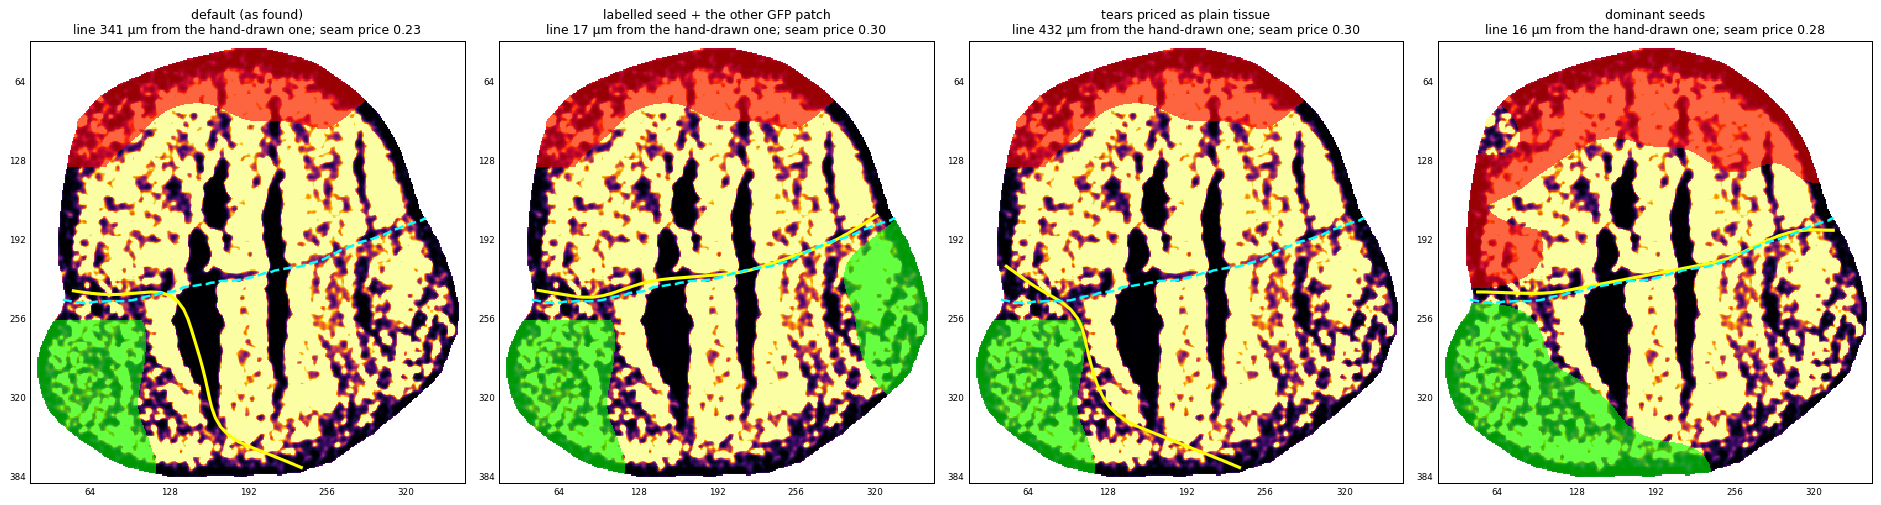

In [23]:
patches, count = ndimage.label((norm > 0.5) & F.filled)
sizes = np.bincount(patches.ravel())[1:]
second_patch = patches == (np.argsort(sizes)[::-1][1] + 1)        # the second-largest GFP patch
wider = jn.split_tissue(F.filled, F.density, F.um, F.cost, seeds=(F.hot | second_patch, F.cold), bend_um=F.options.bend_um)
tried = [("default (as found)", F.halves, F.hot, F.cold),
         ("labelled seed + the other GFP patch", wider, F.hot | second_patch, F.cold)]
for name, change in (("tears priced as plain tissue", {"tear_price": 1.0}), ("dominant seeds", {"seed_rule": "dominant"})):
    again = jn.find_junction(F.overview, jn.JunctionOptions(**{**F.options.__dict__, **change}))
    tried.append((name, again.halves, *again.seeds))

fig, axes = plt.subplots(1, 4, figsize=(21, 5.8))
for ax, (name, sides, a, b) in zip(axes, tried):
    line = line_of(sides, F.um)
    mean, hd95, within = off_by(F, line)
    signs = jn.cut_signs(sides, F.cost, F.um)
    pixels(ax, np.where(F.filled, F.cost, np.nan), "", cmap="inferno", vmin=0, vmax=1)
    tint(ax, a, "lime", 0.6); tint(ax, b, "red", 0.6)
    auto(ax, line, F.um, lw=2.5)
    hand(ax, F, lw=2)
    limits(ax, F.view)
    ax.set_title(f"{name}\nline {mean:.0f} µm from the hand-drawn one; seam price {signs['Cut price']:.2f}")
    print(f"{name:38s}: mean {mean:4.0f} µm, HD95 {hd95:4.0f} µm, {100 * within:3.0f} % within 100 µm, "
          f"seam price {signs['Cut price']:.2f}")
plt.tight_layout()

**3. Why nothing was flagged.** The flags read figures that all look normal here (step 9): the seam price is *low* (the line runs along something very dark, so it looks like a clear junction), the labelled half is 20 % of the section (the flag needs under 10 %), and the density contrast is just above its cut of 1.8.

### What it shows

- **The seed is small and in a corner.** The GFP density of the labelled organoid has two dense patches, one at each end. `find_seeds` keeps only the largest, the lower-left corner. The cut is free to separate that corner from the other seed any way it likes; it does not have to cross the whole section.
- **The tear is the cheapest road.** The section has long open tears running from the junction down to the lower edge. Empty of nuclei, they sit at the price floor. The finder's line runs down one: 29 % of it is on a tear (11 % for the hand-drawn line, which crosses their tops), and its price × length is well under half that of the hand-drawn line (figure 1's printout). The hand-drawn junction itself is faint here: its mean price is about 0.5, a weaker dark line than on the worked section (0.37).
- **The bending price does not save it.** On the worked section the minimum cut also left the junction down a crack (step 5), and the bending price of step 5b pulled it back. Here the saving from the tear is larger than the price of the one turn needed to reach it, so the straightened cut still goes down the tear (step 5b, second figure).
- **The seed is the cause, the tear the road.** With the labelled seed also covering the other GFP patch, the line lands about 17 µm from the hand-drawn one, as good as on the worked section. Pricing the tears as plain tissue alone does **not** fix it: the cut, still free to wrap round the small corner seed, runs down just beside the tear instead (figure 2). Dominant seeds also fix this section; on the 30 annotated sections they were better held out but worse on the tuning set, so they are not the default ([junction_evaluation.ipynb](../validation/junction_evaluation.ipynb), *No clear junction*).
- **The status cannot see it.** A line down a tear looks like a confident line: dark (low seam price), smooth enough, long. The *ok* status only says no check fired; it does not certify where the line is. That is why the QC pictures and the *Junction review* panel exist: here a glance at the picture shows the band in the wrong place.

## Takeaways

- Every step of the finder is a short, local operation on overview pixels: a median, a blur, a ratio, a threshold, a graph cut, a skeleton. On the worked section each step does what it is meant to, and the line ends a mean 15 µm from the hand-drawn one.
- The price map (step 4) is not only the junction: cracks, tears and the section's rim are dark lines too. What keeps the cut on the junction is the **seeds** (which tissue it has to separate) and the **bending price** (no corners).
- When the labelled seed covers only part of its organoid and a tear or crack leads from the junction to the edge, the cut can take the short way round the seed. The worked section survives that thanks to the bending price; the failed section does not.
- Nothing in the status catches this case. Look at the QC picture of every section, and redraw by hand where the band is visibly off: the hand-drawn band is stored as `manual annotated junction region` and used in preference to the automatic one.